<a href="https://colab.research.google.com/github/mdelgiudicechaves-art/Trabalho-SSD---MVP---Final/blob/main/MVP_Unificado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP — Clusterização de clientes e estratégia comercial
**Universidade de Brasília - Departamento de Engenharia de Produção - Prof. André Luiz Marques Serrano**
Pipeline de dados em nuvem - Base: *Customer Personality Analysis* (Kaggle)

Este notebook é a **versão unificada** do MVP: coleta → Bronze → Silver → Gold (esquema estrela) → catálogo de dados → análise P1–P5 → discussão e playbook, **em um único arquivo executável de ponta a ponta**.

| Onde roda | Camadas e tabelas | Persistência |
|---|---|---|
| **Databricks** (Free Edition) | Delta Lake no Unity Catalog (`catalogo.schema.tabela`) + SQL em Spark | Nuvem do Databricks (evidência oficial do MVP) |
| **Google Colab / local** | DuckDB (`mvp.duckdb`) + Parquet por tabela, mesmo SQL das visões | Pasta `saida/` (ou Google Drive, com `MONTAR_DRIVE = True`) |

O ambiente é detectado sozinho. **Todos os números e textos de discussão abaixo são gerados pela execução** (nada digitado à mão), e as saídas ficam gravadas no próprio `.ipynb`, de modo que o GitHub exibe os resultados sem precisar rodar.

### Como usar
1. Execute as células em ordem (*Ambiente → Executar tudo*). Só a célula de configuração (seção 2) pede edição, principalmente `DATA_CONFERENCIA_LICENCA`.
2. Ao final, baixe `mvp_unb_resultados.zip` (figuras, catálogo, tabelas e `resultados_resumo.json`).
3. Para a prova de nuvem exigida no PDF, rode também no Databricks e capture as evidências (seção 11).

### Índice
1. Objetivo e perguntas · 2. Configuração · 3. Coleta · 4. Bronze · 5. Qualidade de dados · 6. Silver · 7. Gold (estrela e K-Means) · 8. Catálogo de dados · 9. Análise P1–P5 · 10. Ética e LGPD · 11. Exportação e evidências

## 1. Objetivo, perguntas de negócio e origem dos dados

**Problema.** A empresa trata a base de clientes de forma homogênea.
**Hipótese.** Existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes; priorizar o orçamento comercial por segmento aumenta o retorno.

**Perguntas de negócio** (mantidas integralmente, mesmo que alguma não seja respondida):

- **P1.** Quantos segmentos naturais de clientes existem (K-Means sobre RFM + perfil demográfico) e qual o perfil de cada um em renda, composição familiar, gasto e frequência?
- **P2.** Qual a contribuição de cada segmento para a receita total e o gasto médio por cliente? Que fração dos clientes concentra 80% do gasto (Pareto)?
- **P3.** Como os segmentos diferem em mix de categorias (vinhos, carnes, peixes, frutas, doces, ouro) e em canal (loja, web, catálogo)? Qual o papel das visitas web e das compras com desconto?
- **P4.** Qual a taxa de aceitação das campanhas (1 a 5 e a última) por segmento? Sob a premissa declarada custo por contato = `Z_CostContact` e receita por aceite = `Z_Revenue`, qual segmento tem melhor retorno estimado? *(O significado de `Z_*` é uma premissa, pois a base não o documenta.)*
- **P5.** Quais clientes têm alto gasto histórico e recência alta (risco de inatividade) e que ação de retenção/reativação faz sentido para eles?

**Entrega final de negócio:** playbook comercial com uma ação recomendada por segmento (oferta, canal, prioridade).

**Origem dos dados.** Kaggle — *Customer Personality Analysis* (`imakash3011/customer-personality-analysis`), arquivo `marketing_campaign.csv`, separado por TAB, 2.240 linhas × 29 colunas.
**Licença.** CC0 (domínio público), conforme a página do dataset — *confirme na página no dia da entrega e preencha `DATA_CONFERENCIA_LICENCA`*.
**Data de coleta, volume, formato e hash:** registrados automaticamente na seção 3.

## 2. Configuração (única célula de parâmetros)

In [1]:
# ============================ CONFIGURAÇÃO ÚNICA ============================
import os
# --- Dados -------------------------------------------------------------------
KAGGLE_DATASET = "imakash3011/customer-personality-analysis"
CSV_NAME = "marketing_campaign.csv"
CSV_LOCAL_PATH = os.environ.get("MVP_CSV_LOCAL", "")
LICENCA_DADOS = "CC0: Public Domain"
DATA_CONFERENCIA_LICENCA = "02/11/2026"
SHA256_PRIMEIRA_EXECUCAO = "cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948f722af81abc6b990ea"  # hash do CSV usado em 21/10/2026

# --- Databricks (Unity Catalog; Free Edition usa o catálogo "workspace") -------
CATALOG, SCHEMA, VOLUME = "workspace", "mvp_marketing", "raw"

# --- Colab -------------------------------------------------------------------
MONTAR_DRIVE = False           # True = grava a saída no Google Drive (persistência em nuvem no Colab)

# --- Parâmetros do modelo e das regras ----------------------------------------
SEED = 42
K_MAX = 8                      # testa k de 2 até K_MAX
K_MIN_ESCOLHA = 3              # k escolhido = maior silhouette com k >= K_MIN_ESCOLHA
PCT_RISCO_GASTO = 0.75         # P5: alto gasto = acima deste percentil
PCT_RISCO_RECENCIA = 0.75      # P5: recência alta (dias sem comprar) = acima deste percentil
N_CONTATOS_POR_CLIENTE = 6     # premissa P4: cada cliente recebeu as 6 campanhas (1 a 5 + última)
REMOVER_DUPLICATAS = True      # R11: remove registros idênticos exceto o ID (a Bronze preserva todos)

In [2]:
# Dependências leves (já presentes no Colab/Databricks; instala só o que faltar)
import importlib, subprocess, sys
def _garantir(pacote, modulo=None):
    try:
        importlib.import_module(modulo or pacote)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", pacote], check=True,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
_garantir("duckdb"); _garantir("kagglehub")

### 2.1 Núcleo de lógica (funções puras, reutilizáveis)
As próximas células definem as funções do pipeline em ordem de uso: **base e mapeamentos** → **qualidade** → **Silver** → **K-Means** → **Gold** → **catálogo** → **análise**. Cada função é chamada logo depois, na seção correspondente.

In [3]:
# ============================================================
# NÚCLEO DE LÓGICA DO MVP — parte 1: bases, mapeamentos e nomes
# Funções puras em pandas/scikit-learn (2.240 linhas: pandas basta e é testável).
# ============================================================
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             davies_bouldin_score, calinski_harabasz_score)

RENOMEAR = {
    "ID": "cliente_id", "Year_Birth": "ano_nascimento", "Education": "educacao_original",
    "Marital_Status": "estado_civil_original", "Income": "renda",
    "Kidhome": "filhos_criancas", "Teenhome": "filhos_adolescentes",
    "Dt_Customer": "data_cadastro", "Recency": "recencia_dias",
    "MntWines": "gasto_vinhos", "MntFruits": "gasto_frutas", "MntMeatProducts": "gasto_carnes",
    "MntFishProducts": "gasto_peixes", "MntSweetProducts": "gasto_doces", "MntGoldProds": "gasto_ouro",
    "NumDealsPurchases": "compras_desconto", "NumWebPurchases": "compras_web",
    "NumCatalogPurchases": "compras_catalogo", "NumStorePurchases": "compras_loja",
    "NumWebVisitsMonth": "visitas_web_mes",
    "AcceptedCmp1": "campanha_1", "AcceptedCmp2": "campanha_2", "AcceptedCmp3": "campanha_3",
    "AcceptedCmp4": "campanha_4", "AcceptedCmp5": "campanha_5", "Response": "campanha_ultima",
    "Complain": "reclamacao_2anos",
}
CATEGORIAS = ["vinhos", "carnes", "peixes", "frutas", "doces", "ouro"]
COLS_GASTO = [f"gasto_{c}" for c in CATEGORIAS]
COLS_CAMPANHA = ["campanha_1", "campanha_2", "campanha_3", "campanha_4", "campanha_5", "campanha_ultima"]
COLS_ORIGINAIS_GASTO = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
COLS_ORIGINAIS_CANAL = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
COLS_ORIGINAIS_BINARIAS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4",
                           "AcceptedCmp5", "Complain", "Response"]
MAP_EDUCACAO = {  # original -> (padronizada, nível ordinal)
    "Basic": ("Básico", 1), "Graduation": ("Graduação", 2),
    "2n Cycle": ("Mestrado", 3),  # premissa: 2n Cycle = 2º ciclo (Bologna) ~ mestrado
    "Master": ("Mestrado", 3), "PhD": ("Doutorado", 4),
}
MAP_ESTADO_CIVIL = {  # original -> (padronizado, grupo)
    "Married": ("Casado(a)", "Com parceiro(a)"), "Together": ("União estável", "Com parceiro(a)"),
    "Single": ("Solteiro(a)", "Sem parceiro(a)"), "Alone": ("Solteiro(a)", "Sem parceiro(a)"),
    "Divorced": ("Divorciado(a)", "Sem parceiro(a)"), "Widow": ("Viúvo(a)", "Sem parceiro(a)"),
    "Absurd": ("Não informado", "Não informado"), "YOLO": ("Não informado", "Não informado"),
}
FEATURES_CLUSTER = ["recencia_dias", "compras_total", "gasto_total_log", "renda", "idade", "n_filhos"]


def _num(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="raise")
    return df


def tipar_bronze(bronze):
    """Bronze (tudo texto) -> DataFrame tipado, sem as colunas de metadados de ingestão."""
    df = bronze[[c for c in bronze.columns if not c.startswith("_")]].copy()
    return _num(df, [c for c in df.columns if c not in ("Education", "Marital_Status", "Dt_Customer")])

In [4]:
# ---------- AMBIENTE: Databricks (Delta + Unity Catalog) ou Colab/local (DuckDB + Parquet) ----------
import os, sys, json, hashlib, uuid, shutil, warnings, datetime as dt
from pathlib import Path
warnings.filterwarnings("ignore")

try:
    spark  # noqa: F821  (existe só no Databricks)
    AMBIENTE = "databricks"
except NameError:
    AMBIENTE = "colab" if Path("/content").exists() else "local"

try:
    display  # noqa: F821
except NameError:
    from IPython.display import display

if AMBIENTE == "databricks":
    SAIDA = Path(f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/saida")
elif AMBIENTE == "colab":
    if MONTAR_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        SAIDA = Path("/content/drive/MyDrive/mvp_unb/saida")
    else:
        SAIDA = Path("/content/mvp_unb/saida")
else:
    SAIDA = Path("mvp_unb") / "saida"
try:
    SAIDA.mkdir(parents=True, exist_ok=True)
except Exception as e:  # volume sem permissão de escrita: cai para pasta temporária
    print("Aviso: não foi possível escrever em", SAIDA, "->", repr(e)[:120])
    SAIDA = Path("/tmp/mvp_unb/saida"); SAIDA.mkdir(parents=True, exist_ok=True)
EVID, CAT, TAB = SAIDA / "evidencias", SAIDA / "catalogo", SAIDA / "tabelas"
for _p in (EVID, CAT, TAB):
    _p.mkdir(parents=True, exist_ok=True)

if AMBIENTE == "databricks":
    def T(nome):
        return f"{CATALOG}.{SCHEMA}.{nome}"

    def sql(q):
        return spark.sql(q).toPandas()

    def sql_exec(q):
        spark.sql(q)

    def pct_sql(col, p):
        return f"percentile_approx({col}, {p})"

    def preparar_camada():
        spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
        spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")

    def salvar_tabela(df, nome):
        (spark.createDataFrame(df).write.format("delta").mode("overwrite")
              .option("overwriteSchema", "true").saveAsTable(T(nome)))

    def ler_tabela(nome):
        return spark.table(T(nome)).toPandas()
else:
    try:
        import duckdb
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "duckdb"], check=True)
        import duckdb
    (SAIDA / "lake").mkdir(exist_ok=True)
    con = duckdb.connect(str(SAIDA / "lake" / "mvp.duckdb"))

    def T(nome):
        return f"{SCHEMA}.{nome}"

    def sql(q):
        df = con.sql(q).df()
        for c in df.columns:  # HUGEINT/Decimal -> número comum
            if df[c].dtype == object:
                try:
                    df[c] = pd.to_numeric(df[c])
                except (ValueError, TypeError):
                    pass
        return df

    def sql_exec(q):
        con.execute(q)

    def pct_sql(col, p):
        return f"quantile_disc({col}, {p})"

    def preparar_camada():
        con.execute(f"CREATE SCHEMA IF NOT EXISTS {SCHEMA}")

    def salvar_tabela(df, nome):
        con.register("_tmp_df", df)
        con.execute(f"CREATE OR REPLACE TABLE {T(nome)} AS SELECT * FROM _tmp_df")
        con.unregister("_tmp_df")
        con.execute(f"COPY {T(nome)} TO '{SAIDA / 'lake' / (nome + '.parquet')}' (FORMAT PARQUET)")

    def ler_tabela(nome):
        return con.sql(f"SELECT * FROM {T(nome)}").df()

print(f"Ambiente: {AMBIENTE} | saída: {SAIDA}")

Ambiente: colab | saída: /content/mvp_unb/saida


## 3. Coleta
Ordem de tentativa: **(1)** arquivo já existente (`CSV_LOCAL_PATH`, Volume do Databricks ou pasta de saída); **(2)** download via `kagglehub` (dataset público, normalmente sem login); **(3)** API do Kaggle com `kaggle.json`; **(4)** upload manual (Colab).

O código registra automaticamente **data, linhas/colunas, tamanho e hash sha256** do arquivo, que são a base da reprodutibilidade (seção 3.2 do PDF).

In [5]:
import glob
destino = SAIDA.parent / CSV_NAME if AMBIENTE == "databricks" else SAIDA.parent / "dados" / CSV_NAME   # Databricks: o próprio Volume raw
destino.parent.mkdir(parents=True, exist_ok=True)
fonte = None

def _copiar(origem):
    if Path(origem).resolve() != destino.resolve():
        shutil.copy(origem, destino)

# (1) arquivo já existente
if CSV_LOCAL_PATH and Path(CSV_LOCAL_PATH).exists():
    _copiar(CSV_LOCAL_PATH); fonte = f"arquivo local informado ({Path(CSV_LOCAL_PATH).name})"
elif destino.exists():
    fonte = "arquivo já existente (reaproveitado)"

# (2) kagglehub
if fonte is None:
    try:
        import kagglehub
        pasta = kagglehub.dataset_download(KAGGLE_DATASET)
        achados = glob.glob(f"{pasta}/**/{CSV_NAME}", recursive=True)
        if not achados:
            raise FileNotFoundError(f"{CSV_NAME} não está em {pasta}")
        _copiar(achados[0]); fonte = f"kagglehub ({KAGGLE_DATASET})"
    except Exception as e:
        print("kagglehub indisponível:", repr(e)[:200])

# (3) API do Kaggle com kaggle.json / variáveis de ambiente
if fonte is None:
    try:
        tem_cred = (Path.home() / ".kaggle" / "kaggle.json").exists() or ("KAGGLE_KEY" in os.environ)
        if not tem_cred:
            raise RuntimeError("sem credenciais do Kaggle (kaggle.json)")
        os.system(f"kaggle datasets download -d {KAGGLE_DATASET} -p {destino.parent} --unzip -q")
        if not destino.exists():
            raise FileNotFoundError("download pela API não gerou o CSV")
        fonte = f"Kaggle API ({KAGGLE_DATASET})"
    except Exception as e:
        print("API do Kaggle indisponível:", repr(e)[:200])

# (4) upload manual
if fonte is None:
    try:
        from google.colab import files
        print("Selecione o arquivo marketing_campaign.csv no seu computador:")
        enviados = files.upload()
        shutil.move(next(iter(enviados)), destino); fonte = "upload manual"
    except ImportError:
        raise SystemExit(f"Não foi possível obter o CSV. Coloque-o em {destino} (ou defina CSV_LOCAL_PATH) e rode novamente.")

raw = pd.read_csv(destino, sep="\t")
if raw.shape[1] == 1:   # separador inesperado: tenta detectar
    raw = pd.read_csv(destino, sep=None, engine="python")

sha = hashlib.sha256(destino.read_bytes()).hexdigest()
meta = {"fonte": fonte, "dataset": KAGGLE_DATASET, "arquivo": CSV_NAME, "licenca": LICENCA_DADOS,
        "data_conferencia_licenca": DATA_CONFERENCIA_LICENCA,
        "data_coleta_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "linhas": int(raw.shape[0]), "colunas": int(raw.shape[1]), "tamanho_bytes": destino.stat().st_size,
        "sha256": sha, "formato": "CSV separado por TAB, UTF-8", "ambiente": AMBIENTE,
        "mesma_versao_da_primeira_execucao": sha == SHA256_PRIMEIRA_EXECUCAO}
(CAT / "metadados_coleta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(meta, indent=2, ensure_ascii=False))
if raw.shape != (2240, 29):
    print(f"\nATENÇÃO: esperado (2240, 29), obtido {raw.shape}. Verifique se é a mesma versão do dataset.")
raw.head()

Using Colab cache for faster access to the 'customer-personality-analysis' dataset.
{
  "fonte": "kagglehub (imakash3011/customer-personality-analysis)",
  "dataset": "imakash3011/customer-personality-analysis",
  "arquivo": "marketing_campaign.csv",
  "licenca": "CC0: Public Domain",
  "data_conferencia_licenca": "02/11/2026",
  "data_coleta_utc": "2026-11-08T23:55:45+00:00",
  "linhas": 2240,
  "colunas": 29,
  "tamanho_bytes": 220188,
  "sha256": "cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948f722af81abc6b990ea",
  "formato": "CSV separado por TAB, UTF-8",
  "ambiente": "colab",
  "mesma_versao_da_primeira_execucao": true
}


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## 4. Bronze — dado bruto, sem alteração de conteúdo
Lê o CSV com **todas as colunas como texto** (sem inferência de tipos) e acrescenta metadados de ingestão (`_ingestao_ts`, `_arquivo_origem`, `_lote_id`). Tipagem e limpeza ficam para a Silver. A Bronze **preserva todos os registros**, inclusive os duplicados.

In [6]:
preparar_camada()
bronze = pd.read_csv(destino, sep="\t", dtype=str)
bronze["_ingestao_ts"] = pd.Timestamp.now()
bronze["_arquivo_origem"] = str(destino)
bronze["_lote_id"] = str(uuid.uuid4())
assert len(bronze) == len(raw) and bronze.shape[1] == raw.shape[1] + 3, "Bronze não confere com o CSV"
salvar_tabela(bronze, "bronze_marketing_campaign")
print(f"Tabela criada: {T('bronze_marketing_campaign')} | {len(bronze)} linhas × {bronze.shape[1]} colunas (com metadados)")
display(sql(f"SELECT COUNT(*) AS linhas FROM {T('bronze_marketing_campaign')}"))
bronze.head(5)

Tabela criada: mvp_marketing.bronze_marketing_campaign | 2240 linhas × 32 colunas (com metadados)


,linhas
0,2240


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,_ingestao_ts,_arquivo_origem,_lote_id
0,5524,1957,Graduation,Single,58138,0,0,04-09-2012,58,635,...,0,0,0,0,3,11,1,2026-11-08 23:55:45.923781,/content/mvp_unb/dados/marketing_campaign.csv,8e6d4224-d611-49f4-83cc-82923ef2bd69
1,2174,1954,Graduation,Single,46344,1,1,08-03-2014,38,11,...,0,0,0,0,3,11,0,2026-11-08 23:55:45.923781,/content/mvp_unb/dados/marketing_campaign.csv,8e6d4224-d611-49f4-83cc-82923ef2bd69
2,4141,1965,Graduation,Together,71613,0,0,21-08-2013,26,426,...,0,0,0,0,3,11,0,2026-11-08 23:55:45.923781,/content/mvp_unb/dados/marketing_campaign.csv,8e6d4224-d611-49f4-83cc-82923ef2bd69
3,6182,1984,Graduation,Together,26646,1,0,10-02-2014,26,11,...,0,0,0,0,3,11,0,2026-11-08 23:55:45.923781,/content/mvp_unb/dados/marketing_campaign.csv,8e6d4224-d611-49f4-83cc-82923ef2bd69
4,5324,1981,PhD,Married,58293,1,0,19-01-2014,94,173,...,0,0,0,0,3,11,0,2026-11-08 23:55:45.923781,/content/mvp_unb/dados/marketing_campaign.csv,8e6d4224-d611-49f4-83cc-82923ef2bd69


## 5. Análise de qualidade de dados (por atributo)
Dimensões examinadas: **completude** (nulos), **unicidade** (duplicatas), **consistência** (contradições entre atributos), **conformidade** (aderência ao domínio), **acurácia** (valores implausíveis) e **atualidade**.

> **Achado importante:** a checagem de unicidade só por *linha inteira* e por *ID* não encontra nada. Comparando **todos os atributos exceto o ID**, aparecem registros repetidos com outro ID (ver abaixo).

In [7]:
# ---------- QUALIDADE DE DADOS (sobre o dado bruto) -----------------------------
def perfil_atributos(df):
    """Uma linha por atributo: tipo, nulos, únicos, mín/máx, outliers (IQR 1,5) e observações."""
    linhas = []
    for c in df.columns:
        s = df[c]
        num = pd.api.types.is_numeric_dtype(s)
        obs = []
        if s.nunique(dropna=False) == 1:
            obs.append("constante")
        out = np.nan
        if num and s.nunique() > 2:
            q1, q3 = s.quantile([.25, .75])
            iqr = q3 - q1
            out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
        linhas.append({"atributo": c, "tipo": str(s.dtype), "nulos": int(s.isna().sum()),
                       "% nulos": round(100 * s.isna().mean(), 2), "únicos": int(s.nunique()),
                       "mín": s.min() if num else "", "máx": s.max() if num else "",
                       "outliers_IQR": out, "obs": ", ".join(obs)})
    return pd.DataFrame(linhas)


def duplicatas_sem_id(raw):
    """Registros idênticos em TODOS os atributos, exceto o ID (re-chaveados).
    Devolve DataFrame com (cliente_id_removido, cliente_id_mantido, grupo); mantém o menor ID de cada grupo."""
    cols = [c for c in raw.columns if c != "ID" and not c.startswith("_")]
    d = raw.sort_values("ID").reset_index(drop=True)
    grupo = d.groupby(cols, dropna=False, sort=False).ngroup()
    d = d.assign(_grupo=grupo)
    mantido = d.groupby("_grupo")["ID"].transform("min")
    extra = d[d["ID"] != mantido]
    return pd.DataFrame({"cliente_id_removido": extra["ID"].astype(int).values,
                         "cliente_id_mantido": mantido[extra.index].astype(int).values,
                         "grupo": extra["_grupo"].values}).reset_index(drop=True)


def testes_qualidade(raw):
    """Testes por dimensão de qualidade (completude, unicidade, consistência, conformidade, acurácia, atualidade)."""
    datas = pd.to_datetime(raw["Dt_Customer"], format="%d-%m-%Y", errors="coerce")
    compras = raw[COLS_ORIGINAIS_CANAL].sum(axis=1)
    idade_ref = datas.max().year - raw["Year_Birth"]
    q1, q3 = raw["Income"].quantile([.25, .75])
    n_dup = len(duplicatas_sem_id(raw))
    anos_defasagem = int(pd.Timestamp.today().year - datas.max().year)
    num_cols = [c for c in raw.columns if c not in ("Education", "Marital_Status", "Dt_Customer")]
    t = [
        ("Completude", "Income", "valores nulos", int(raw["Income"].isna().sum()), "Imputar pela mediana do nível de educação (R3)"),
        ("Completude", "demais colunas", "nulos fora de Income", int(raw.drop(columns="Income").isna().sum().sum()), "Nenhuma ação"),
        ("Unicidade", "linha inteira", "linhas duplicadas (com ID)", int(raw.duplicated().sum()), "Nenhuma ação"),
        ("Unicidade", "ID", "IDs duplicados", int(raw["ID"].duplicated().sum()), "Nenhuma ação"),
        ("Unicidade", "todos os atributos exceto ID", "registros repetidos com outro ID (duplicatas re-chaveadas)", n_dup,
         "Remover da Silver mantendo o menor ID; Bronze preserva tudo (R11)"),
        ("Consistência", "NumDealsPurchases vs canais", "compras com desconto > compras totais", int((raw["NumDealsPurchases"] > compras).sum()), "Manter e limitar % a 1 (R9)"),
        ("Consistência", "compras", "clientes com 0 compras mas gasto > 0", int(((compras == 0) & (raw[COLS_ORIGINAIS_GASTO].sum(axis=1) > 0)).sum()), "Manter; ticket/shares = 0 (R10)"),
        ("Conformidade", "Dt_Customer", "datas fora do formato dd-mm-aaaa", int(datas.isna().sum()), "Conversão explícita (R2)"),
        ("Conformidade", "Marital_Status", "categorias fora do domínio esperado (Alone/Absurd/YOLO)", int(raw["Marital_Status"].isin(["Alone", "Absurd", "YOLO"]).sum()), "Recodificar (R6)"),
        ("Conformidade", "Education", "categoria '2n Cycle' (nomenclatura distinta)", int((raw["Education"] == "2n Cycle").sum()), "Padronizar como Mestrado, preservando original (R7)"),
        ("Conformidade", "binárias", "valores fora de {0,1}", int(sum((~raw[c].isin([0, 1])).sum() for c in COLS_ORIGINAIS_BINARIAS)), "Nenhuma ação"),
        ("Conformidade", "Kidhome, Teenhome", "valores fora de 0–2", int(sum((~raw[c].between(0, 2)).sum() for c in ["Kidhome", "Teenhome"])), "Nenhuma ação"),
        ("Conformidade", "Recency", "valores fora de 0–99 dias", int((~raw["Recency"].between(0, 99)).sum()), "Nenhuma ação"),
        ("Conformidade", "Mnt*, Num*", "valores negativos em gastos/compras", int(sum((raw[c] < 0).sum() for c in COLS_ORIGINAIS_GASTO + COLS_ORIGINAIS_CANAL + ["NumDealsPurchases", "NumWebVisitsMonth"])), "Nenhuma ação"),
        ("Conformidade", "Z_CostContact, Z_Revenue", "colunas constantes", int(sum(raw[c].nunique() == 1 for c in ["Z_CostContact", "Z_Revenue"])), "Descartar; usar só como premissa de P4 (R1)"),
        ("Acurácia", "Year_Birth", "idade > 100 anos na data de referência", int((idade_ref > 100).sum()), "Imputar idade pela mediana (R5)"),
        ("Acurácia", "Income", "outlier extremo (> Q3+3·IQR)", int((raw["Income"] > q3 + 3 * (q3 - q1)).sum()), "Tratar como erro e imputar (R4)"),
        ("Atualidade", "Dt_Customer", f"cadastros de {datas.min().date()} a {datas.max().date()} (anos até hoje: {anos_defasagem})", anos_defasagem,
         "Dados defasados; registrar como limitação"),
    ]
    return pd.DataFrame(t, columns=["dimensão", "atributo", "teste", "ocorrências", "decisão"])

In [8]:
perfil_q = perfil_atributos(raw)
perfil_q.to_csv(CAT / "qualidade_por_atributo.csv", index=False)
pd.set_option("display.width", 200, "display.max_rows", 100, "display.max_columns", 40)
perfil_q

,atributo,tipo,nulos,% nulos,únicos,mín,máx,outliers_IQR,obs
0,ID,int64,0,0.00,2240,0,11191,0.0,
1,Year_Birth,int64,0,0.00,59,1893,1996,3.0,
2,Education,object,0,0.00,5,,,NaN,
3,Marital_Status,object,0,0.00,8,,,NaN,
4,Income,float64,24,1.07,1974,1730.0,666666.0,8.0,
5,Kidhome,int64,0,0.00,3,0,2,0.0,
6,Teenhome,int64,0,0.00,3,0,2,0.0,
7,Dt_Customer,object,0,0.00,663,,,NaN,
8,Recency,int64,0,0.00,100,0,99,0.0,
9,MntWines,int64,0,0.00,776,0,1493,35.0,


In [9]:
qualidade = testes_qualidade(raw)
qualidade.to_csv(CAT / "qualidade_testes.csv", index=False)
qualidade

,dimensão,atributo,teste,ocorrências,decisão
0,Completude,Income,valores nulos,24,Imputar pela mediana do nível de educação (R3)
1,Completude,demais colunas,nulos fora de Income,0,Nenhuma ação
2,Unicidade,linha inteira,linhas duplicadas (com ID),0,Nenhuma ação
3,Unicidade,ID,IDs duplicados,0,Nenhuma ação
4,Unicidade,todos os atributos exceto ID,registros repetidos com outro ID (duplicatas r...,182,Remover da Silver mantendo o menor ID; Bronze ...
5,Consistência,NumDealsPurchases vs canais,compras com desconto > compras totais,3,Manter e limitar % a 1 (R9)
6,Consistência,compras,clientes com 0 compras mas gasto > 0,6,Manter; ticket/shares = 0 (R10)
7,Conformidade,Dt_Customer,datas fora do formato dd-mm-aaaa,0,Conversão explícita (R2)
8,Conformidade,Marital_Status,categorias fora do domínio esperado (Alone/Abs...,7,Recodificar (R6)
9,Conformidade,Education,categoria '2n Cycle' (nomenclatura distinta),203,"Padronizar como Mestrado, preservando original..."


In [10]:
# Duplicatas re-chaveadas: mesmos 28 atributos, ID diferente
dup_raw = duplicatas_sem_id(raw)
cols_sem_id = [c for c in raw.columns if c != "ID"]
grupos = (raw[raw.duplicated(subset=cols_sem_id, keep=False)].sort_values(cols_sem_id + ["ID"])
          .groupby(cols_sem_id, dropna=False)["ID"].apply(list).reset_index(drop=True))
print(f"{len(dup_raw)} registros extras em {len(grupos)} grupos de duplicatas (tamanho máximo do grupo: {grupos.apply(len).max()}).")
print("Exemplos de grupos de IDs com todos os demais atributos idênticos:", grupos.head(5).tolist())
dup_raw.to_csv(CAT / "duplicatas_detectadas.csv", index=False)

182 registros extras em 176 grupos de duplicatas (tamanho máximo do grupo: 3).
Exemplos de grupos de IDs com todos os demais atributos idênticos: [[2968, 8800], [4939, 8652], [7881, 10562], [455, 7592], [2114, 4261]]


## 6. Silver — tipagem, regras de negócio e features
| Problema | Decisão | Justificativa |
|---|---|---|
| Registros repetidos com outro ID (**R11**) | Remover da Silver, mantendo o menor ID; a Bronze guarda tudo | Com 28 atributos idênticos (data de cadastro, renda, 15 gastos/compras...) a coincidência é improvável: dupla contagem distorceria K-Means, receita e taxas. `REMOVER_DUPLICATAS=False` mantém e apenas sinaliza |
| `Income` nulo (24) (**R3**) | Imputar pela **mediana de renda do mesmo nível de educação** | Renda varia com escolaridade; a mediana é robusta a outliers. `flag_renda_imputada` preserva a rastreabilidade |
| `Income` = 666.666 (**R4**) | Erro de digitação (> Q3 + 3·IQR) → nulo → imputar | É ~4× o segundo maior valor; distorceria média, escala e K-Means |
| `Year_Birth` < 1900 (**R5**) | Idade > 100 → imputar mediana | Poucos casos; remover perderia o cliente. `flag_idade_corrigida` |
| Idade e tempo de cliente (**R2**) | Calcular em relação à **maior `Dt_Customer`** | Dados de 2012–2014; usar a data de hoje inflaria a idade de todos |
| `Marital_Status` Alone/Absurd/YOLO (**R6**) | Alone → Solteiro(a); Absurd e YOLO → "Não informado" | Evita inventar valor; preserva a coluna original |
| `Education` "2n Cycle" (**R7**) | Padronizar como Mestrado (premissa), mantendo o original | 2º ciclo (Bologna) ≈ mestrado |
| `Z_CostContact`, `Z_Revenue` (**R1**) | Descartar da Silver; usar como **premissa** de P4 | Constantes: sem poder discriminante |
| Compras com desconto > compras totais (**R9**), clientes sem compras (**R10**) | Manter e sinalizar; limitar % a 1 | Inconsistências pequenas, registradas |

In [11]:
# ---------- SILVER: tipagem, qualidade e features ---------------------------------
def silver_transform(raw, remover_duplicatas=True):
    """Recebe o Bronze (pandas) e devolve (silver, log, constantes, duplicatas).
    log = DataFrame {regra, afetados, decisao} que documenta cada regra de negócio.
    duplicatas = DataFrame (cliente_id_removido, cliente_id_mantido) — vazio se remover_duplicatas=False."""
    log = []
    df = raw[[c for c in raw.columns if not c.startswith("_")]].copy()  # remove metadados de ingestão
    textos = ["Education", "Marital_Status", "Dt_Customer"]
    df = _num(df, [c for c in df.columns if c not in textos])

    # R11. Duplicatas re-chaveadas: todos os atributos iguais, exceto ID (executada primeiro)
    dup = duplicatas_sem_id(df)
    if remover_duplicatas and len(dup):
        df = df[~df["ID"].isin(dup["cliente_id_removido"])].copy()
        acao = ("Removidos da Silver (mantido o menor ID de cada grupo); a Bronze preserva todos os registros. "
                "Evita dupla contagem no K-Means, na receita e nas taxas de campanha")
    else:
        acao = "Mantidos (REMOVER_DUPLICATAS=False): apenas sinalizados em flag_duplicata"
    ids_dup = set(dup["cliente_id_removido"])
    df = df.sort_values("ID").reset_index(drop=True)
    df["flag_duplicata"] = df["ID"].isin(ids_dup)
    log.append({"regra": "R11 Duplicatas (atributos idênticos, ID diferente)", "afetados": int(len(dup)), "decisao": acao})

    # R1. Colunas constantes não carregam informação -> descartadas (valores guardados como premissa de P4)
    constantes = {c: df[c].iloc[0] for c in df.columns
                  if c != "flag_duplicata" and df[c].nunique(dropna=False) == 1}
    df = df.drop(columns=list(constantes))
    vals = [int(v) if float(v).is_integer() else float(v) for v in constantes.values()]
    log.append({"regra": "R1 Colunas constantes", "afetados": len(constantes),
                "decisao": f"Descartadas {list(constantes)} (valores {vals}); "
                           "mantidos só como premissa de custo/receita em P4"})

    df = df.rename(columns=RENOMEAR)

    # R2. Datas: Dt_Customer vem como dd-mm-aaaa
    df["data_cadastro"] = pd.to_datetime(df["data_cadastro"], format="%d-%m-%Y", errors="raise")
    data_ref = df["data_cadastro"].max()  # idade/tempo calculados na data de referência da base, não hoje
    log.append({"regra": "R2 Data de referência", "afetados": len(df),
                "decisao": f"data_ref = max(Dt_Customer) = {data_ref.date()}; idade e tempo de cliente calculados nela"})

    # R3/R4. Renda: nulos + outlier extremo (> Q3 + 3*IQR) -> NaN -> imputação pela mediana do nível de educação
    q1, q3 = df["renda"].quantile([.25, .75])
    limite = q3 + 3 * (q3 - q1)
    m_out = df["renda"] > limite
    m_nulo = df["renda"].isna()
    df["flag_renda_outlier"] = m_out
    df["flag_renda_imputada"] = m_out | m_nulo
    base = df.loc[~(m_out | m_nulo)]
    med_educ = base.groupby("educacao_original")["renda"].median()
    df.loc[m_out, "renda"] = np.nan
    df["renda"] = df["renda"].fillna(df["educacao_original"].map(med_educ)).fillna(base["renda"].median())
    log.append({"regra": "R3 Renda nula", "afetados": int(m_nulo.sum()),
                "decisao": "Imputada pela mediana de renda do mesmo nível de educação (flag_renda_imputada)"})
    log.append({"regra": "R4 Renda outlier extremo", "afetados": int(m_out.sum()),
                "decisao": f"Valores > {limite:,.0f} (Q3+3·IQR) tratados como erro de digitação: viram nulo e são imputados"})

    # R5. Idade implausível
    df["idade"] = data_ref.year - df["ano_nascimento"]
    m_idade = (df["idade"] > 100) | (df["idade"] < 16)
    df["flag_idade_corrigida"] = m_idade
    df.loc[m_idade, "idade"] = np.nan
    df["idade"] = df["idade"].fillna(df["idade"].median()).astype(int)
    df["ano_nascimento"] = (data_ref.year - df["idade"]).astype(int)
    log.append({"regra": "R5 Idade implausível", "afetados": int(m_idade.sum()),
                "decisao": "Idade > 100 ou < 16 na data de referência vira nulo e é imputada pela mediana (flag_idade_corrigida)"})

    # R6/R7. Padronização de categorias
    desconhecidas = set(df["educacao_original"]) - set(MAP_EDUCACAO)
    desconhecidas |= set(df["estado_civil_original"]) - set(MAP_ESTADO_CIVIL)
    if desconhecidas:
        raise ValueError(f"Categorias não mapeadas: {desconhecidas}. Atualize MAP_EDUCACAO / MAP_ESTADO_CIVIL.")
    df["educacao"] = df["educacao_original"].map(lambda x: MAP_EDUCACAO[x][0])
    df["educacao_nivel"] = df["educacao_original"].map(lambda x: MAP_EDUCACAO[x][1])
    df["estado_civil"] = df["estado_civil_original"].map(lambda x: MAP_ESTADO_CIVIL[x][0])
    df["estado_civil_grupo"] = df["estado_civil_original"].map(lambda x: MAP_ESTADO_CIVIL[x][1])
    n_est = int(df["estado_civil_original"].isin(["Alone", "Absurd", "YOLO"]).sum())
    log.append({"regra": "R6 Estado civil", "afetados": n_est,
                "decisao": "Alone -> Solteiro(a); Absurd e YOLO -> 'Não informado' (mantidos, sem inferir valor)"})
    log.append({"regra": "R7 Educação '2n Cycle'", "afetados": int((df["educacao_original"] == "2n Cycle").sum()),
                "decisao": "Premissa: 2º ciclo (Bologna) equivale a Mestrado; coluna original preservada"})

    # R8. Features derivadas
    df["gasto_total"] = df[COLS_GASTO].sum(axis=1)
    df["compras_total"] = df[["compras_web", "compras_catalogo", "compras_loja"]].sum(axis=1)  # canais; desconto é subconjunto
    df["n_filhos"] = df["filhos_criancas"] + df["filhos_adolescentes"]
    df["tempo_cliente_dias"] = (data_ref - df["data_cadastro"]).dt.days
    df["flag_sem_compras"] = df["compras_total"] == 0
    comp = df["compras_total"].replace(0, np.nan)
    df["ticket_medio"] = (df["gasto_total"] / comp).fillna(0.0)
    for canal in ["web", "catalogo", "loja"]:
        df[f"share_{canal}"] = (df[f"compras_{canal}"] / comp).fillna(0.0)
    df["pct_compras_desconto"] = (df["compras_desconto"] / comp).clip(upper=1).fillna(0.0)
    for c in CATEGORIAS:
        df[f"pct_gasto_{c}"] = df[f"gasto_{c}"] / df["gasto_total"].replace(0, np.nan)
        df[f"pct_gasto_{c}"] = df[f"pct_gasto_{c}"].fillna(0.0)
    df["n_campanhas_aceitas"] = df[COLS_CAMPANHA[:5]].sum(axis=1)  # campanhas 1 a 5
    log.append({"regra": "R8 Features", "afetados": len(df),
                "decisao": "gasto_total, compras_total (web+catálogo+loja; desconto é subconjunto), n_filhos, "
                           "tempo_cliente_dias, ticket_medio, share por canal, pct por categoria, n_campanhas_aceitas"})
    n_desc = int((df["compras_desconto"] > df["compras_total"]).sum())
    log.append({"regra": "R9 Consistência: compras com desconto > compras totais", "afetados": n_desc,
                "decisao": "Mantidos; pct_compras_desconto limitado a 1 (inconsistência registrada, não corrigida)"})
    log.append({"regra": "R10 Clientes sem compras", "afetados": int(df["flag_sem_compras"].sum()),
                "decisao": "Mantidos (têm gasto > 0); ticket médio e shares ficam 0 (flag_sem_compras)"})

    ordem = ["cliente_id", "ano_nascimento", "idade", "data_cadastro", "educacao_original", "educacao",
             "educacao_nivel", "estado_civil_original", "estado_civil", "estado_civil_grupo", "renda",
             "filhos_criancas", "filhos_adolescentes", "n_filhos", "recencia_dias", "tempo_cliente_dias"]
    resto = [c for c in df.columns if c not in ordem]
    df = df[ordem + resto].reset_index(drop=True)
    for c in ["flag_renda_outlier", "flag_renda_imputada", "flag_idade_corrigida", "flag_sem_compras", "flag_duplicata"]:
        df[c] = df[c].astype(bool)

    log_df = pd.DataFrame(log)
    log_df["_n"] = log_df["regra"].str.extract(r"R(\d+)")[0].astype(int)
    log_df = log_df.sort_values("_n").drop(columns="_n").reset_index(drop=True)
    dup_out = dup if remover_duplicatas else dup.iloc[0:0]
    return df, log_df, {k: float(v) for k, v in constantes.items()}, dup_out.reset_index(drop=True)

In [12]:
silver, log_regras, constantes, duplicatas = silver_transform(bronze, remover_duplicatas=REMOVER_DUPLICATAS)
print("Silver:", silver.shape, "| Bronze:", bronze.shape)
log_regras.to_csv(CAT / "regras_transformacao.csv", index=False)
log_regras

Silver: (2058, 53) | Bronze: (2240, 32)


,regra,afetados,decisao
0,R1 Colunas constantes,2,"Descartadas ['Z_CostContact', 'Z_Revenue'] (va..."
1,R2 Data de referência,2058,data_ref = max(Dt_Customer) = 2014-06-29; idad...
2,R3 Renda nula,24,Imputada pela mediana de renda do mesmo nível ...
3,R4 Renda outlier extremo,1,"Valores > 167,338 (Q3+3·IQR) tratados como err..."
4,R5 Idade implausível,3,Idade > 100 ou < 16 na data de referência vira...
5,R6 Estado civil,7,Alone -> Solteiro(a); Absurd e YOLO -> 'Não in...
6,R7 Educação '2n Cycle',188,Premissa: 2º ciclo (Bologna) equivale a Mestra...
7,R8 Features,2058,"gasto_total, compras_total (web+catálogo+loja;..."
8,R9 Consistência: compras com desconto > compra...,3,Mantidos; pct_compras_desconto limitado a 1 (i...
9,R10 Clientes sem compras,6,Mantidos (têm gasto > 0); ticket médio e share...


In [13]:
# Checagens automáticas antes de gravar
n_esperado = len(bronze) - (len(duplicatas) if REMOVER_DUPLICATAS else 0)
assert len(silver) == n_esperado, "Silver perdeu/duplicou linhas além das duplicatas removidas"
assert silver["cliente_id"].is_unique, "cliente_id duplicado"
assert silver.isna().sum().sum() == 0, "Silver não deveria ter nulos após o tratamento"
assert (silver["gasto_total"] >= 0).all()
assert not silver.duplicated(subset=[c for c in silver.columns if c not in ("cliente_id", "flag_duplicata")]).any() or not REMOVER_DUPLICATAS
print("Checagens OK")

salvar_tabela(silver, "silver_clientes")
salvar_tabela(log_regras.astype(str), "silver_regras_negocio")
salvar_tabela(pd.DataFrame({"coluna": list(constantes.keys()), "valor": list(constantes.values())}), "silver_constantes")
salvar_tabela(duplicatas if len(duplicatas) else pd.DataFrame({"cliente_id_removido": pd.Series(dtype="int64"), "cliente_id_mantido": pd.Series(dtype="int64"), "grupo": pd.Series(dtype="int64")}),
              "silver_duplicatas_removidas")
display(sql(f"SELECT COUNT(*) AS linhas FROM {T('silver_clientes')}"))

Checagens OK


,linhas
0,2058


## 7. Gold — K-Means e esquema estrela
1. **K-Means** sobre RFM + perfil (`recencia_dias`, `compras_total`, `log(gasto_total)`, `renda`, `idade`, `n_filhos`), padronizados (z-score).
2. **k** = maior *silhouette* entre `K_MIN_ESCOLHA` e `K_MAX` (inércia/cotovelo, Davies–Bouldin e Calinski–Harabasz como apoio). Estabilidade medida por **5 sementes** (ARI) e por **reamostragem bootstrap**.
3. **Esquema estrela (constelação de fatos):** `fato_cliente_vendas` (grão = cliente) e duas fatos de grão fino, `fato_campanha_resposta` (cliente × campanha) e `fato_gasto_categoria` (cliente × categoria), ligadas às dimensões de cliente, tempo, educação, estado civil, segmento, campanha e categoria.
4. **Visões SQL** usadas na análise (mesmo SQL no Databricks e no DuckDB).

In [14]:
# ---------- CLUSTERIZAÇÃO ---------------------------------------------------------
def matriz_cluster(silver):
    X = silver.copy()
    X["gasto_total_log"] = np.log1p(X["gasto_total"])  # reduz assimetria do gasto
    return StandardScaler().fit_transform(X[FEATURES_CLUSTER])


def clusterizar(silver, k_plot_min=2, k_max=8, k_min_escolha=3, seed=42, seeds_estab=(1, 7, 21, 42, 99), n_boot=30):
    """K-Means. Escolhe k pelo maior silhouette em [k_min_escolha, k_max].
    Estabilidade: (a) ARI entre sementes e (b) ARI em reamostragens bootstrap (ajusta na amostra, classifica a base toda)."""
    Z = matriz_cluster(silver)
    linhas = []
    for k in range(k_plot_min, k_max + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(Z)
        linhas.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                       "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
    metricas = pd.DataFrame(linhas)
    elegiveis = metricas[metricas["k"] >= k_min_escolha]
    k = int(elegiveis.loc[elegiveis["silhouette"].idxmax(), "k"])
    base = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(Z).labels_
    aris = [adjusted_rand_score(base, KMeans(n_clusters=k, n_init=20, random_state=s).fit(Z).labels_)
            for s in seeds_estab]
    rng = np.random.default_rng(seed)
    boot = []
    for b in range(n_boot):
        idx = rng.choice(len(Z), len(Z), replace=True)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=seed + b).fit(Z[idx])
        boot.append(adjusted_rand_score(base, km_b.predict(Z)))
    sil = metricas.set_index("k")["silhouette"]
    estab = {"k": k, "k_min_escolha": int(k_min_escolha), "k_max": int(k_max), "silhouette_k": float(sil[k]), "silhouette_k2": float(sil[2]) if 2 in sil.index else float("nan"),
             "ari_medio": float(np.mean(aris)), "ari_min": float(np.min(aris)), "sementes": list(seeds_estab),
             "boot_n": n_boot, "boot_ari_medio": float(np.mean(boot)), "boot_ari_p05": float(np.percentile(boot, 5))}
    # ordena segmentos por gasto médio decrescente: S1 = maior gasto
    tmp = pd.DataFrame({"lab": base, "gasto": silver["gasto_total"].values})
    ordem = tmp.groupby("lab")["gasto"].mean().sort_values(ascending=False).index.tolist()
    novo = {lab: i + 1 for i, lab in enumerate(ordem)}
    seg_id = pd.Series(base).map(novo).astype(int).values
    return seg_id, metricas, estab


def rotulo_segmento(i, k):
    if i == 1:
        return f"S{i} - maior gasto"
    if i == k:
        return f"S{i} - menor gasto"
    return f"S{i} - gasto intermediário"

In [15]:
# ---------- GOLD: esquema estrela (constelação de fatos) -----------------------------
def construir_gold(silver, seg_id):
    """Fato central (grão = cliente) + duas fatos de grão fino (cliente×campanha e cliente×categoria),
    todas ligadas às dimensões de cliente, tempo, educação, estado civil, segmento, campanha e categoria."""
    s = silver.copy()
    s["segmento_id"] = seg_id
    k = int(s["segmento_id"].max())

    dim_educacao = (s[["educacao_original", "educacao", "educacao_nivel"]].drop_duplicates()
                    .sort_values(["educacao_nivel", "educacao_original"]).reset_index(drop=True))
    dim_educacao.insert(0, "educacao_id", range(1, len(dim_educacao) + 1))
    dim_estado = (s[["estado_civil", "estado_civil_grupo"]].drop_duplicates()
                  .sort_values("estado_civil").reset_index(drop=True))
    dim_estado.insert(0, "estado_civil_id", range(1, len(dim_estado) + 1))

    datas = pd.Series(pd.to_datetime(s["data_cadastro"].unique())).sort_values()
    dim_tempo = pd.DataFrame({"data": datas.values})
    dim_tempo.insert(0, "data_id", dim_tempo["data"].dt.strftime("%Y%m%d").astype(int))
    dim_tempo["ano"] = dim_tempo["data"].dt.year
    dim_tempo["trimestre"] = dim_tempo["data"].dt.quarter
    dim_tempo["mes"] = dim_tempo["data"].dt.month
    dim_tempo["dia_semana"] = dim_tempo["data"].dt.dayofweek + 1  # 1=segunda
    dim_tempo["ano_mes"] = dim_tempo["data"].dt.strftime("%Y-%m")

    dim_cliente = s[["cliente_id", "ano_nascimento", "idade", "renda", "n_filhos", "filhos_criancas",
                     "filhos_adolescentes", "flag_renda_outlier", "flag_renda_imputada",
                     "flag_idade_corrigida"]].copy()
    dim_cliente["faixa_etaria"] = pd.cut(dim_cliente["idade"], [0, 34, 44, 54, 64, 200],
                                         labels=["até 34", "35-44", "45-54", "55-64", "65+"]).astype(str)
    dim_cliente["faixa_renda"] = pd.qcut(dim_cliente["renda"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]).astype(str)
    dim_cliente["tem_filhos"] = dim_cliente["n_filhos"] > 0

    agg = s.groupby("segmento_id").agg(n_clientes=("cliente_id", "count"), gasto_medio=("gasto_total", "mean"),
                                       renda_media=("renda", "mean"), recencia_media=("recencia_dias", "mean")).reset_index()
    agg["rotulo"] = [rotulo_segmento(i, k) for i in agg["segmento_id"]]
    dim_segmento = agg[["segmento_id", "rotulo", "n_clientes", "gasto_medio", "renda_media", "recencia_media"]]

    nomes_camp = ["Campanha 1", "Campanha 2", "Campanha 3", "Campanha 4", "Campanha 5", "Última campanha"]
    dim_campanha = pd.DataFrame({"campanha_id": range(1, 7), "campanha_col": COLS_CAMPANHA, "nome": nomes_camp,
                                 "coluna_kaggle": ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4",
                                                   "AcceptedCmp5", "Response"]})
    dim_categoria = pd.DataFrame({"categoria_id": range(1, 7), "categoria": [c.capitalize() for c in CATEGORIAS],
                                  "coluna_origem": COLS_GASTO, "coluna_kaggle": COLS_ORIGINAIS_GASTO})

    fato = s.merge(dim_educacao[["educacao_id", "educacao_original"]], on="educacao_original") \
            .merge(dim_estado[["estado_civil_id", "estado_civil"]], on="estado_civil")
    fato["data_id"] = fato["data_cadastro"].dt.strftime("%Y%m%d").astype(int)
    cols_fato = (["cliente_id", "educacao_id", "estado_civil_id", "data_id", "segmento_id", "recencia_dias",
                  "tempo_cliente_dias", "gasto_total"] + COLS_GASTO +
                 [f"pct_gasto_{c}" for c in CATEGORIAS] +
                 ["compras_total", "compras_web", "compras_catalogo", "compras_loja", "compras_desconto",
                  "visitas_web_mes", "ticket_medio", "share_web", "share_catalogo", "share_loja",
                  "pct_compras_desconto"] + COLS_CAMPANHA + ["n_campanhas_aceitas", "reclamacao_2anos", "flag_sem_compras"])
    fato = fato[cols_fato].sort_values("cliente_id").reset_index(drop=True)
    assert len(fato) == len(s), "O join da fato duplicou ou perdeu clientes"

    fc = (s[["cliente_id", "segmento_id"] + COLS_CAMPANHA]
          .melt(id_vars=["cliente_id", "segmento_id"], var_name="campanha_col", value_name="aceitou")
          .merge(dim_campanha[["campanha_id", "campanha_col"]], on="campanha_col"))
    fc["aceitou"] = fc["aceitou"].astype(int)
    fc["contatado_premissa"] = 1  # premissa de P4: todo cliente foi contatado em todas as campanhas
    fato_campanha = (fc[["cliente_id", "campanha_id", "segmento_id", "aceitou", "contatado_premissa"]]
                     .sort_values(["cliente_id", "campanha_id"]).reset_index(drop=True))

    fg = (s[["cliente_id", "segmento_id"] + COLS_GASTO]
          .melt(id_vars=["cliente_id", "segmento_id"], var_name="coluna_origem", value_name="gasto")
          .merge(dim_categoria[["categoria_id", "coluna_origem"]], on="coluna_origem"))
    fato_gasto_cat = (fg[["cliente_id", "categoria_id", "segmento_id", "gasto"]]
                      .sort_values(["cliente_id", "categoria_id"]).reset_index(drop=True))

    return {"dim_cliente": dim_cliente, "dim_educacao": dim_educacao, "dim_estado_civil": dim_estado,
            "dim_tempo": dim_tempo, "dim_segmento": dim_segmento, "dim_campanha": dim_campanha,
            "dim_categoria": dim_categoria, "fato_cliente_vendas": fato,
            "fato_campanha_resposta": fato_campanha, "fato_gasto_categoria": fato_gasto_cat}


def checar_integridade(gold):
    """Chaves únicas, chaves estrangeiras sem órfãos e totais batendo entre as fatos. Levanta erro se algo falhar."""
    fv, fc, fg = gold["fato_cliente_vendas"], gold["fato_campanha_resposta"], gold["fato_gasto_categoria"]
    chk = []

    def uni(tab, col):
        chk.append((f"PK única: {tab}.{col}", bool(gold[tab][col].is_unique)))

    def fk(tab_f, col, tab_d, col_d=None):
        col_d = col_d or col
        chk.append((f"FK sem órfãos: {tab_f}.{col} -> {tab_d}.{col_d}", bool(gold[tab_f][col].isin(gold[tab_d][col_d]).all())))

    for t, c in [("dim_cliente", "cliente_id"), ("dim_educacao", "educacao_id"), ("dim_estado_civil", "estado_civil_id"),
                 ("dim_tempo", "data_id"), ("dim_segmento", "segmento_id"), ("dim_campanha", "campanha_id"),
                 ("dim_categoria", "categoria_id"), ("fato_cliente_vendas", "cliente_id")]:
        uni(t, c)
    for c, d in [("cliente_id", "dim_cliente"), ("educacao_id", "dim_educacao"), ("estado_civil_id", "dim_estado_civil"),
                 ("data_id", "dim_tempo"), ("segmento_id", "dim_segmento")]:
        fk("fato_cliente_vendas", c, d)
    for f in ["fato_campanha_resposta", "fato_gasto_categoria"]:
        fk(f, "cliente_id", "dim_cliente"); fk(f, "segmento_id", "dim_segmento")
    fk("fato_campanha_resposta", "campanha_id", "dim_campanha"); fk("fato_gasto_categoria", "categoria_id", "dim_categoria")
    chk.append(("Fato de campanha = clientes × 6", len(fc) == 6 * len(fv)))
    chk.append(("Fato de gasto = clientes × 6 categorias", len(fg) == 6 * len(fv)))
    chk.append(("Σ gasto (fato_gasto_categoria) = Σ gasto_total", bool(np.isclose(fg["gasto"].sum(), fv["gasto_total"].sum()))))
    chk.append(("Σ aceites (fato_campanha_resposta) = Σ colunas de campanha", int(fc["aceitou"].sum()) == int(fv[COLS_CAMPANHA].sum().sum())))
    res = pd.DataFrame(chk, columns=["verificação", "ok"])
    if not res["ok"].all():
        raise AssertionError("Integridade do esquema estrela falhou:\n" + res[~res["ok"]].to_string())
    return res

In [16]:
seg_id, metricas, estab = clusterizar(silver, k_max=K_MAX, k_min_escolha=K_MIN_ESCOLHA, seed=SEED)
print(f"k escolhido = {estab['k']} | silhouette = {estab['silhouette_k']:.3f}  (k=2 teria {estab['silhouette_k2']:.3f})")
print(f"Estabilidade entre sementes {estab['sementes']}: ARI médio = {estab['ari_medio']:.3f} | mínimo = {estab['ari_min']:.3f}")
print(f"Estabilidade bootstrap ({estab['boot_n']} reamostragens): ARI médio = {estab['boot_ari_medio']:.3f} | percentil 5 = {estab['boot_ari_p05']:.3f}")
metricas.round(3)

k escolhido = 3 | silhouette = 0.263  (k=2 teria 0.335)
Estabilidade entre sementes [1, 7, 21, 42, 99]: ARI médio = 0.999 | mínimo = 0.998
Estabilidade bootstrap (30 reamostragens): ARI médio = 0.853 | percentil 5 = 0.406


,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,7626.004,0.335,1.211,1273.072
1,3,6674.621,0.263,1.482,873.371
2,4,5856.096,0.217,1.682,759.002
3,5,5289.133,0.219,1.535,684.982
4,6,4835.794,0.207,1.461,637.539
5,7,4427.742,0.216,1.381,611.478
6,8,4182.346,0.219,1.331,571.777


In [17]:
gold = construir_gold(silver, seg_id)
integridade = checar_integridade(gold)
display(integridade)
ordem_escrita = ["dim_cliente", "dim_educacao", "dim_estado_civil", "dim_tempo", "dim_segmento", "dim_campanha", "dim_categoria",
                 "fato_cliente_vendas", "fato_campanha_resposta", "fato_gasto_categoria"]
for nome in ordem_escrita:
    salvar_tabela(gold[nome], nome)
    print(f"{nome:24s} {len(gold[nome]):>7,} linhas")

salvar_tabela(metricas, "gold_clusterizacao_metricas")
estab_df = pd.DataFrame([{"k": estab["k"], "silhouette": estab["silhouette_k"], "ari_medio": estab["ari_medio"], "ari_min": estab["ari_min"],
                          "boot_ari_medio": estab["boot_ari_medio"], "boot_ari_p05": estab["boot_ari_p05"], "boot_n": estab["boot_n"],
                          "sementes": str(estab["sementes"]), "seed_base": SEED}])
salvar_tabela(estab_df, "gold_clusterizacao_estabilidade")

# Premissas de P4 (Z_* é premissa: a base não documenta o significado)
CUSTO_CONTATO, RECEITA_ACEITE = constantes["Z_CostContact"], constantes["Z_Revenue"]
prem = pd.DataFrame([{"custo_contato": CUSTO_CONTATO, "receita_aceite": RECEITA_ACEITE, "contatos_por_cliente": N_CONTATOS_POR_CLIENTE}])
salvar_tabela(prem, "gold_premissas_p4")
prem

,verificação,ok
0,PK única: dim_cliente.cliente_id,True
1,PK única: dim_educacao.educacao_id,True
2,PK única: dim_estado_civil.estado_civil_id,True
3,PK única: dim_tempo.data_id,True
4,PK única: dim_segmento.segmento_id,True
5,PK única: dim_campanha.campanha_id,True
6,PK única: dim_categoria.categoria_id,True
7,PK única: fato_cliente_vendas.cliente_id,True
8,FK sem órfãos: fato_cliente_vendas.cliente_id ...,True
9,FK sem órfãos: fato_cliente_vendas.educacao_id...,True


dim_cliente                2,058 linhas
dim_educacao                   5 linhas
dim_estado_civil               6 linhas
dim_tempo                    663 linhas
dim_segmento                   3 linhas
dim_campanha                   6 linhas
dim_categoria                  6 linhas
fato_cliente_vendas        2,058 linhas
fato_campanha_resposta    12,348 linhas
fato_gasto_categoria      12,348 linhas


,custo_contato,receita_aceite,contatos_por_cliente
0,3.0,11.0,6


In [18]:
# ---------- VISÕES ANALÍTICAS (SQL único, roda em Spark SQL e em DuckDB) ---------------------
def sql_views(T, pct_fn, pct_gasto=0.75, pct_rec=0.75):
    """Devolve {nome_da_view: SQL}. T(nome) qualifica a tabela; pct_fn(coluna, p) é o percentil discreto do motor
    (Spark: percentile_approx; DuckDB: quantile_disc)."""
    v = {}
    v["vw_perfil_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       COUNT(*) AS n_clientes,
       ROUND(AVG(c.renda),0) AS renda_media,
       ROUND(AVG(c.idade),1) AS idade_media,
       ROUND(AVG(c.n_filhos),2) AS filhos_medio,
       ROUND(AVG(CASE WHEN c.tem_filhos THEN 1 ELSE 0 END),3) AS pct_com_filhos,
       ROUND(AVG(f.gasto_total),0) AS gasto_medio,
       ROUND(AVG(f.compras_total),1) AS compras_media,
       ROUND(AVG(f.recencia_dias),1) AS recencia_media,
       ROUND(AVG(f.ticket_medio),1) AS ticket_medio,
       ROUND(AVG(f.visitas_web_mes),2) AS visitas_web_media,
       ROUND(AVG(f.tempo_cliente_dias),0) AS tempo_cliente_medio
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_cliente')} c ON f.cliente_id = c.cliente_id
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_receita_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       COUNT(*) AS n_clientes,
       SUM(f.gasto_total) AS gasto_total_segmento,
       ROUND(SUM(f.gasto_total) / SUM(SUM(f.gasto_total)) OVER (), 4) AS pct_receita,
       ROUND(COUNT(*) / SUM(COUNT(*)) OVER (), 4) AS pct_clientes,
       ROUND(AVG(f.gasto_total),1) AS gasto_medio_cliente
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_mix_canal_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       SUM(f.gasto_vinhos)/SUM(f.gasto_total) AS mix_vinhos,
       SUM(f.gasto_carnes)/SUM(f.gasto_total) AS mix_carnes,
       SUM(f.gasto_peixes)/SUM(f.gasto_total) AS mix_peixes,
       SUM(f.gasto_frutas)/SUM(f.gasto_total) AS mix_frutas,
       SUM(f.gasto_doces)/SUM(f.gasto_total) AS mix_doces,
       SUM(f.gasto_ouro)/SUM(f.gasto_total) AS mix_ouro,
       SUM(f.compras_loja)/SUM(f.compras_total) AS canal_loja,
       SUM(f.compras_web)/SUM(f.compras_total) AS canal_web,
       SUM(f.compras_catalogo)/SUM(f.compras_total) AS canal_catalogo,
       SUM(f.compras_desconto)/SUM(f.compras_total) AS pct_compras_desconto,
       AVG(f.visitas_web_mes) AS visitas_web_media
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_gasto_categoria_segmento"] = f"""
SELECT s.segmento_id, s.rotulo, k.categoria,
       SUM(g.gasto) AS gasto,
       SUM(g.gasto) / SUM(SUM(g.gasto)) OVER (PARTITION BY s.segmento_id) AS pct_no_segmento
FROM {T('fato_gasto_categoria')} g
JOIN {T('dim_segmento')} s ON g.segmento_id = s.segmento_id
JOIN {T('dim_categoria')} k ON g.categoria_id = k.categoria_id
GROUP BY s.segmento_id, s.rotulo, k.categoria"""
    v["vw_campanhas_segmento"] = f"""
SELECT s.segmento_id, s.rotulo, COUNT(*) AS n_clientes,
       AVG(f.campanha_1) AS taxa_c1, AVG(f.campanha_2) AS taxa_c2, AVG(f.campanha_3) AS taxa_c3,
       AVG(f.campanha_4) AS taxa_c4, AVG(f.campanha_5) AS taxa_c5, AVG(f.campanha_ultima) AS taxa_ultima,
       SUM(f.campanha_1+f.campanha_2+f.campanha_3+f.campanha_4+f.campanha_5+f.campanha_ultima) AS aceites,
       COUNT(*) * MAX(p.contatos_por_cliente) AS contatos,
       COUNT(*) * MAX(p.contatos_por_cliente) * MAX(p.custo_contato) AS custo_estimado,
       SUM(f.campanha_1+f.campanha_2+f.campanha_3+f.campanha_4+f.campanha_5+f.campanha_ultima) * MAX(p.receita_aceite) AS receita_estimada
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
CROSS JOIN {T('gold_premissas_p4')} p
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_campanha_segmento_campanha"] = f"""
SELECT s.segmento_id, s.rotulo, c.campanha_id, c.nome AS campanha,
       SUM(f.contatado_premissa) AS contatos, SUM(f.aceitou) AS aceites,
       AVG(f.aceitou) AS taxa
FROM {T('fato_campanha_resposta')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
JOIN {T('dim_campanha')} c ON f.campanha_id = c.campanha_id
GROUP BY s.segmento_id, s.rotulo, c.campanha_id, c.nome"""
    v["vw_clientes_risco"] = f"""
WITH lim AS (
  SELECT {pct_fn('gasto_total', pct_gasto)} AS lim_gasto,
         {pct_fn('recencia_dias', pct_rec)} AS lim_rec
  FROM {T('fato_cliente_vendas')})
SELECT f.cliente_id, s.rotulo, f.gasto_total, f.recencia_dias, f.compras_total,
       f.compras_loja, f.compras_web, f.compras_catalogo, f.n_campanhas_aceitas, f.campanha_ultima,
       lim.lim_gasto, lim.lim_rec
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
CROSS JOIN lim
WHERE f.gasto_total >= lim.lim_gasto AND f.recencia_dias >= lim.lim_rec"""
    return v

In [19]:
# Cria as visões analíticas (SQL)
for nome_view, consulta in sql_views(T, pct_sql, PCT_RISCO_GASTO, PCT_RISCO_RECENCIA).items():
    sql_exec(f"CREATE OR REPLACE VIEW {T(nome_view)} AS {consulta}")
    print("visão criada:", T(nome_view))
perfil = sql(f"SELECT * FROM {T('vw_perfil_segmento')} ORDER BY segmento_id")
perfil

visão criada: mvp_marketing.vw_perfil_segmento
visão criada: mvp_marketing.vw_receita_segmento
visão criada: mvp_marketing.vw_mix_canal_segmento
visão criada: mvp_marketing.vw_gasto_categoria_segmento
visão criada: mvp_marketing.vw_campanhas_segmento
visão criada: mvp_marketing.vw_campanha_segmento_campanha
visão criada: mvp_marketing.vw_clientes_risco


,segmento_id,rotulo,n_clientes,renda_media,idade_media,filhos_medio,pct_com_filhos,gasto_medio,compras_media,recencia_media,ticket_medio,visitas_web_media,tempo_cliente_medio
0,1,S1 - maior gasto,986,69037.0,47.2,0.56,0.517,1108.0,18.8,48.3,59.8,4.06,375.0
1,2,S2 - gasto intermediário,482,44377.0,50.8,1.87,0.996,201.0,8.0,52.3,20.0,6.11,316.0
2,3,S3 - menor gasto,590,29945.0,37.0,0.87,0.832,99.0,5.8,47.2,17.3,6.78,344.0


## 8. Catálogo de dados e diagrama do modelo
Campos exigidos pelo PDF (seção 3.3): nome, tipo, descrição, domínio (mín/máx ou categorias), obrigatoriedade (nulos e significado da ausência) e linhagem (origem, data de extração, transformações). **Domínios e obrigatoriedade são calculados dos dados**; descrições são texto de negócio. No Databricks, as descrições também são gravadas como **comentários de coluna** no Unity Catalog.

In [20]:
# ---------- CATÁLOGO DE DADOS (descrição, domínio, obrigatoriedade, linhagem) ----------
DESCRICOES = {}
# Colunas originais (conforme descrição do dataset no Kaggle)
DESCRICOES.update({
 "ID": ("Identificador sequencial do cliente (não é identificador direto)", "Original"),
 "Year_Birth": ("Ano de nascimento", "Original"), "Education": ("Nível de escolaridade", "Original"),
 "Marital_Status": ("Estado civil", "Original"), "Income": ("Renda anual do domicílio", "Original; 24 nulos"),
 "Kidhome": ("Nº de crianças no domicílio", "Original"), "Teenhome": ("Nº de adolescentes no domicílio", "Original"),
 "Dt_Customer": ("Data de cadastro do cliente (dd-mm-aaaa)", "Original (texto)"),
 "Recency": ("Dias desde a última compra", "Original"),
 "MntWines": ("Gasto com vinhos nos últimos 2 anos", "Original"), "MntFruits": ("Gasto com frutas nos últimos 2 anos", "Original"),
 "MntMeatProducts": ("Gasto com carnes nos últimos 2 anos", "Original"), "MntFishProducts": ("Gasto com peixes nos últimos 2 anos", "Original"),
 "MntSweetProducts": ("Gasto com doces nos últimos 2 anos", "Original"), "MntGoldProds": ("Gasto com produtos premium (ouro) nos últimos 2 anos", "Original"),
 "NumDealsPurchases": ("Compras feitas com desconto", "Original"), "NumWebPurchases": ("Compras pelo site", "Original"),
 "NumCatalogPurchases": ("Compras por catálogo", "Original"), "NumStorePurchases": ("Compras em loja física", "Original"),
 "NumWebVisitsMonth": ("Visitas ao site no último mês", "Original"),
 "AcceptedCmp1": ("Aceitou a oferta da campanha 1 (1=sim)", "Original"), "AcceptedCmp2": ("Aceitou a oferta da campanha 2 (1=sim)", "Original"),
 "AcceptedCmp3": ("Aceitou a oferta da campanha 3 (1=sim)", "Original"), "AcceptedCmp4": ("Aceitou a oferta da campanha 4 (1=sim)", "Original"),
 "AcceptedCmp5": ("Aceitou a oferta da campanha 5 (1=sim)", "Original"), "Response": ("Aceitou a oferta da última campanha (1=sim)", "Original"),
 "Complain": ("Reclamou nos últimos 2 anos (1=sim)", "Original"),
 "Z_CostContact": ("Constante (=3); significado não documentado; assumido como custo por contato (premissa P4)", "Original; descartada na Silver"),
 "Z_Revenue": ("Constante (=11); significado não documentado; assumido como receita por aceite (premissa P4)", "Original; descartada na Silver"),
 "_ingestao_ts": ("Data/hora da ingestão na Bronze", "Bronze: current_timestamp()"),
 "_arquivo_origem": ("Caminho do arquivo de origem", "Bronze: caminho do CSV"),
 "_lote_id": ("Identificador (UUID) do lote de ingestão", "Bronze: uuid4()"),
})
# Colunas Silver/Gold
DESCRICOES.update({
 "cliente_id": ("Identificador sequencial do cliente (chave)", "Silver: renomeado de ID"),
 "ano_nascimento": ("Ano de nascimento (corrigido se implausível)", "Silver: Year_Birth; recalculado de idade quando corrigida (R5)"),
 "idade": ("Idade em anos na data de referência (maior data de cadastro)", "Silver: ano da data_ref − Year_Birth; >100 ou <16 → mediana (R2, R5)"),
 "renda": ("Renda anual do domicílio (imputada se nula/outlier)", "Silver: Income; nulos e outlier → mediana por educação (R3, R4)"),
 "n_filhos": ("Total de filhos no domicílio", "Silver: Kidhome + Teenhome"),
 "filhos_criancas": ("Nº de crianças no domicílio", "Silver: Kidhome"), "filhos_adolescentes": ("Nº de adolescentes no domicílio", "Silver: Teenhome"),
 "flag_renda_outlier": ("Renda original era outlier extremo", "Silver (R4)"), "flag_renda_imputada": ("Renda foi imputada (nula ou outlier)", "Silver (R3/R4)"),
 "flag_idade_corrigida": ("Idade foi corrigida por implausibilidade", "Silver (R5)"),
 "flag_duplicata": ("Registro era duplicata de outro cliente (só é True se REMOVER_DUPLICATAS=False)", "Silver (R11)"),
 "faixa_etaria": ("Faixa etária (até 34, 35-44, 45-54, 55-64, 65+)", "Gold: corte de idade"),
 "faixa_renda": ("Quartil de renda (Q1 menor … Q4 maior)", "Gold: qcut(renda, 4)"),
 "tem_filhos": ("Possui ao menos um filho no domicílio", "Gold: n_filhos > 0"),
 "educacao_id": ("Chave substituta da dimensão educação", "Gold: sequencial"),
 "educacao_original": ("Escolaridade como na origem", "Silver: Education"),
 "educacao": ("Escolaridade padronizada (Básico, Graduação, Mestrado, Doutorado)", "Silver: 2n Cycle e Master → Mestrado (R7)"),
 "educacao_nivel": ("Nível ordinal da escolaridade (1 a 4)", "Silver: mapeamento ordinal"),
 "estado_civil_id": ("Chave substituta da dimensão estado civil", "Gold: sequencial"),
 "estado_civil_original": ("Estado civil como na origem", "Silver: Marital_Status"),
 "estado_civil": ("Estado civil padronizado", "Silver: Alone→Solteiro(a); Absurd/YOLO→Não informado (R6)"),
 "estado_civil_grupo": ("Com parceiro(a) / Sem parceiro(a) / Não informado", "Silver (R6)"),
 "data_id": ("Chave da data de cadastro (aaaammdd)", "Gold: de Dt_Customer"), "data": ("Data de cadastro", "Silver: Dt_Customer convertido (R2)"),
 "ano": ("Ano da data", "Gold"), "trimestre": ("Trimestre da data", "Gold"), "mes": ("Mês da data", "Gold"),
 "dia_semana": ("Dia da semana (1=segunda)", "Gold"), "ano_mes": ("Ano-mês (aaaa-mm)", "Gold"),
 "data_cadastro": ("Data de cadastro do cliente", "Silver: Dt_Customer convertido (R2)"),
 "segmento_id": ("Segmento do cluster (1 = maior gasto médio)", "Gold: K-Means, ordenado por gasto médio"),
 "rotulo": ("Rótulo do segmento (S1 maior gasto … Sk menor gasto)", "Gold"),
 "n_clientes": ("Nº de clientes no segmento", "Gold: contagem"), "gasto_medio": ("Gasto total médio do segmento", "Gold: média"),
 "renda_media": ("Renda média do segmento", "Gold: média"), "recencia_media": ("Recência média (dias) do segmento", "Gold: média"),
 "recencia_dias": ("Dias desde a última compra", "Silver: Recency"),
 "tempo_cliente_dias": ("Dias entre o cadastro e a data de referência", "Silver: data_ref − Dt_Customer (R2, R8)"),
 "gasto_total": ("Gasto total nas 6 categorias", "Silver: soma de Mnt* (R8)"),
 "compras_total": ("Compras totais (web + catálogo + loja)", "Silver (R8); compras com desconto é subconjunto"),
 "compras_web": ("Compras pelo site", "Silver: NumWebPurchases"), "compras_catalogo": ("Compras por catálogo", "Silver: NumCatalogPurchases"),
 "compras_loja": ("Compras em loja física", "Silver: NumStorePurchases"), "compras_desconto": ("Compras com desconto", "Silver: NumDealsPurchases"),
 "visitas_web_mes": ("Visitas ao site no último mês", "Silver: NumWebVisitsMonth"),
 "ticket_medio": ("Gasto total ÷ compras totais (0 se sem compras)", "Silver (R8, R10)"),
 "share_web": ("% das compras pelo site", "Silver (R8)"), "share_catalogo": ("% das compras por catálogo", "Silver (R8)"),
 "share_loja": ("% das compras em loja", "Silver (R8)"),
 "pct_compras_desconto": ("Compras com desconto ÷ compras totais (máx. 1)", "Silver (R8, R9)"),
 "campanha_1": ("Aceitou campanha 1", "Silver: AcceptedCmp1"), "campanha_2": ("Aceitou campanha 2", "Silver: AcceptedCmp2"),
 "campanha_3": ("Aceitou campanha 3", "Silver: AcceptedCmp3"), "campanha_4": ("Aceitou campanha 4", "Silver: AcceptedCmp4"),
 "campanha_5": ("Aceitou campanha 5", "Silver: AcceptedCmp5"), "campanha_ultima": ("Aceitou a última campanha", "Silver: Response"),
 "n_campanhas_aceitas": ("Nº de campanhas aceitas entre 1 e 5", "Silver (R8)"),
 "reclamacao_2anos": ("Reclamou nos últimos 2 anos", "Silver: Complain"),
 "flag_sem_compras": ("Cliente sem nenhuma compra registrada", "Silver (R10)"),
 "campanha_id": ("Chave da campanha (1 a 5 = campanhas 1–5; 6 = última)", "Gold: sequencial"),
 "campanha_col": ("Nome da coluna de campanha na Silver", "Gold"),
 "nome": ("Nome da campanha", "Gold"),
 "coluna_kaggle": ("Nome da coluna correspondente no CSV original", "Gold"),
 "aceitou": ("1 se o cliente aceitou a oferta da campanha", "Gold: melt das colunas campanha_*"),
 "contatado_premissa": ("1 = premissa de que todo cliente foi contatado em todas as campanhas", "Gold: constante (premissa P4)"),
 "categoria_id": ("Chave da categoria de produto", "Gold: sequencial"),
 "categoria": ("Categoria de produto (Vinhos, Carnes, Peixes, Frutas, Doces, Ouro)", "Gold"),
 "coluna_origem": ("Nome da coluna de gasto na Silver", "Gold"),
 "gasto": ("Gasto do cliente na categoria nos últimos 2 anos", "Gold: melt das colunas gasto_*"),
})
for _c in CATEGORIAS:
    DESCRICOES[f"gasto_{_c}"] = (f"Gasto com {_c}", "Silver: Mnt* correspondente")
    DESCRICOES[f"pct_gasto_{_c}"] = (f"% do gasto total em {_c}", "Silver (R8)")

LINHAGEM_TABELA = {
    "bronze_marketing_campaign": "Kaggle imakash3011/customer-personality-analysis → CSV bruto (sem alterações)",
    "silver_clientes": "Bronze → Silver (regras R1–R11)",
    "fato_cliente_vendas": "Bronze → Silver → Gold", "dim_cliente": "Bronze → Silver → Gold",
    "dim_educacao": "Bronze → Silver → Gold", "dim_estado_civil": "Bronze → Silver → Gold",
    "dim_tempo": "Bronze → Silver → Gold", "dim_segmento": "Silver → K-Means (Gold)",
    "dim_campanha": "Definição manual (Gold)", "dim_categoria": "Definição manual (Gold)",
    "fato_campanha_resposta": "Silver (colunas campanha_*) → Gold (formato longo)",
    "fato_gasto_categoria": "Silver (colunas gasto_*) → Gold (formato longo)",
}


def tipo_dom(s, nome):
    if pd.api.types.is_bool_dtype(s):
        return "booleano", "{False, True}"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "data", f"{s.min().date()} a {s.max().date()}"
    if pd.api.types.is_numeric_dtype(s):
        if nome.endswith("_id") or nome in ("cliente_id", "ID"):
            return "numérico (chave)", f"inteiro, {s.min()} a {s.max()}, únicos={s.nunique()}"
        return "numérico", f"{s.min():g} a {s.max():g}"
    vals = sorted(s.dropna().astype(str).unique())
    if len(vals) <= 12:
        return "categórico", "; ".join(vals)
    return "texto", f"{len(vals)} valores distintos"


def catalogar(tabela, df, extracao, fonte="Kaggle"):
    """Catálogo mínimo exigido (nome, tipo, descrição, domínio, obrigatoriedade, linhagem) para uma tabela."""
    linhas = []
    lin_tab = LINHAGEM_TABELA.get(tabela, "Gold")
    for c in df.columns:
        t, dom = tipo_dom(df[c], c)
        nn = int(df[c].isna().sum())
        obrig = "Obrigatório (0 nulos)" if nn == 0 else f"Admite nulos ({nn}); ausência = valor não informado na origem"
        desc, transf = DESCRICOES.get(c, ("[sem descrição]", "[sem descrição]"))
        linhas.append({"tabela": tabela, "atributo": c, "tipo": t, "descricao": desc, "dominio": dom,
                       "obrigatoriedade": obrig, "linhagem": f"{lin_tab}; extraído em {extracao}; {transf}"})
    return linhas


def catalogo_markdown(catalogo, dataset, licenca, extracao):
    md = ["# Catálogo de Dados\n", f"Dataset: Kaggle `{dataset}` · Licença: {licenca} · Extração: {extracao}\n"]
    for tab, g in catalogo.groupby("tabela", sort=False):
        md.append(f"\n## {tab}\n\n| Atributo | Tipo | Descrição | Domínio | Obrigatoriedade | Linhagem |\n|---|---|---|---|---|---|")
        for r in g.itertuples():
            md.append(f"| {r.atributo} | {r.tipo} | {r.descricao} | {r.dominio} | {r.obrigatoriedade} | {r.linhagem} |")
    return "\n".join(md)

In [21]:
EXTRACAO = meta["data_coleta_utc"][:10]
linhas_cat = catalogar("bronze_marketing_campaign", raw, EXTRACAO)
linhas_cat += catalogar("silver_clientes", silver, EXTRACAO)
for nome in ordem_escrita:
    linhas_cat += catalogar(nome, gold[nome], EXTRACAO)
catalogo = pd.DataFrame(linhas_cat)
faltando = catalogo[catalogo["descricao"] == "[sem descrição]"]["atributo"].unique().tolist()
assert not faltando, f"Atributos sem descrição no catálogo: {faltando}"
catalogo.to_csv(CAT / "catalogo_dados.csv", index=False, encoding="utf-8")
(CAT / "catalogo_dados.md").write_text(catalogo_markdown(catalogo, KAGGLE_DATASET, LICENCA_DADOS, EXTRACAO), encoding="utf-8")
salvar_tabela(catalogo, "gold_catalogo_dados")
print(f"Catálogo: {len(catalogo)} atributos em {catalogo['tabela'].nunique()} tabelas")

if AMBIENTE == "databricks":   # descrições como comentários de coluna no Unity Catalog (falha não interrompe)
    ok = 0
    for r in catalogo[catalogo["tabela"] != "bronze_marketing_campaign"].itertuples():
        try:
            spark.sql(f"ALTER TABLE {T(r.tabela)} ALTER COLUMN `{r.atributo}` COMMENT '{r.descricao.replace(chr(39), '')}'"); ok += 1
        except Exception as e:
            pass
    print(f"Comentários de coluna gravados no Unity Catalog: {ok}")
catalogo.head(12)

Catálogo: 172 atributos em 12 tabelas


,tabela,atributo,tipo,descricao,dominio,obrigatoriedade,linhagem
0,bronze_marketing_campaign,ID,numérico (chave),Identificador sequencial do cliente (não é ide...,"inteiro, 0 a 11191, únicos=2240",Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
1,bronze_marketing_campaign,Year_Birth,numérico,Ano de nascimento,1893 a 1996,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
2,bronze_marketing_campaign,Education,categórico,Nível de escolaridade,2n Cycle; Basic; Graduation; Master; PhD,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
3,bronze_marketing_campaign,Marital_Status,categórico,Estado civil,Absurd; Alone; Divorced; Married; Single; Toge...,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
4,bronze_marketing_campaign,Income,numérico,Renda anual do domicílio,1730 a 666666,Admite nulos (24); ausência = valor não inform...,Kaggle imakash3011/customer-personality-analys...
5,bronze_marketing_campaign,Kidhome,numérico,Nº de crianças no domicílio,0 a 2,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
6,bronze_marketing_campaign,Teenhome,numérico,Nº de adolescentes no domicílio,0 a 2,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
7,bronze_marketing_campaign,Dt_Customer,texto,Data de cadastro do cliente (dd-mm-aaaa),663 valores distintos,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
8,bronze_marketing_campaign,Recency,numérico,Dias desde a última compra,0 a 99,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
9,bronze_marketing_campaign,MntWines,numérico,Gasto com vinhos nos últimos 2 anos,0 a 1493,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...


## 9. Análise
Cada seção traz: consulta (SQL/pandas) → gráfico → **discussão gerada dos números desta execução**. Resultados fracos ou inconclusivos são relatados como tal. As figuras são salvas em `evidencias/` com os nomes sugeridos pelo checklist.

In [22]:
# ============================================================
# CAMADA DE ANÁLISE — parte 1: formatação, estatística e tabelas de apoio
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

# Paleta categórica validada (ordem fixa; os 3 primeiros slots são seguros para dispersão/all-pairs)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TINTA, TINTA_2, MUDO, GRADE, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div_azul_vermelho", ["#2a78d6", "#f0efec", "#e34948"])
CAT_ANALISE = ["vinhos", "carnes", "peixes", "frutas", "doces", "ouro"]


def estilo_graficos():
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2,
        "text.color": TINTA, "xtick.color": MUDO, "ytick.color": MUDO, "axes.titlecolor": TINTA,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE,
        "grid.linewidth": 0.7, "axes.axisbelow": True, "font.size": 9.5, "legend.frameon": False,
        "axes.prop_cycle": plt.cycler(color=PALETA)})


estilo_graficos()


def cores_seg(rotulos):
    """Cor fixa por segmento (S1 = azul, S2 = laranja, S3 = verde-água...), nunca pela posição na tela."""
    rot = sorted(rotulos, key=lambda r: int(str(r).split()[0][1:]))
    return {r: PALETA[i % len(PALETA)] for i, r in enumerate(rot)}


def br(x, nd=0):
    """Número no formato brasileiro: 1.234,5"""
    s = f"{x:,.{nd}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def pct(x, nd=1):
    return br(100 * x, nd) + "%"


def mostrar_md(texto):
    """Mostra markdown no Colab/Jupyter (IPython) ou no Databricks (displayHTML)."""
    g = globals()
    if "displayHTML" in g:
        import html, re
        linhas, out, em_tab, em_lista = texto.split("\n"), [], False, False
        def inline(s):
            s = html.escape(s)
            s = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", s)
            s = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", s)
            return re.sub(r"`(.+?)`", r"<code>\1</code>", s)
        for ln in linhas:
            if ln.startswith("|"):
                cel = [c.strip() for c in ln.strip().strip("|").split("|")]
                if all(set(c) <= set("-: ") for c in cel):
                    continue
                if not em_tab:
                    out.append("<table border='1' cellpadding='4' style='border-collapse:collapse'>"); em_tab = True
                    out.append("<tr>" + "".join(f"<th>{inline(c)}</th>" for c in cel) + "</tr>")
                else:
                    out.append("<tr>" + "".join(f"<td>{inline(c)}</td>" for c in cel) + "</tr>")
                continue
            if em_tab:
                out.append("</table>"); em_tab = False
            if ln.startswith("- "):
                if not em_lista:
                    out.append("<ul>"); em_lista = True
                out.append(f"<li>{inline(ln[2:])}</li>"); continue
            if em_lista:
                out.append("</ul>"); em_lista = False
            if ln.startswith("#"):
                n = len(ln) - len(ln.lstrip("#")); out.append(f"<h{n}>{inline(ln.lstrip('# '))}</h{n}>")
            elif ln.strip():
                out.append(f"<p>{inline(ln)}</p>")
        if em_tab: out.append("</table>")
        if em_lista: out.append("</ul>")
        g["displayHTML"]("\n".join(out))
    else:
        from IPython.display import Markdown, display
        display(Markdown(texto))


def salvar_fig(fig, caminho):
    if caminho:
        from pathlib import Path
        Path(caminho).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(caminho, bbox_inches="tight")


# ---------- estatística de apoio ---------------------------------------------------
def wilson(k, n, z=1.96):
    """Intervalo de confiança de Wilson (95%) para uma proporção k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def pareto(gasto):
    """Curva de Pareto e fração de clientes que concentra 80% do gasto; inclui Gini."""
    g = pd.Series(gasto).sort_values(ascending=False).reset_index(drop=True)
    acum = g.cumsum() / g.sum()
    n80 = int((acum < 0.80).sum() + 1)
    asc = np.sort(g.values.astype(float))
    n = len(asc)
    gini = float((2 * np.arange(1, n + 1) - n - 1).dot(asc) / (n * asc.sum()))
    curva = pd.DataFrame({"pct_acum_clientes": (np.arange(n) + 1) / n, "pct_acum_gasto": acum.values})
    return {"n80": n80, "frac80": n80 / n, "gini": gini, "n": n, "curva": curva}


VARS_CARAC = [("renda", "renda"), ("idade", "idade"), ("n_filhos", "nº de filhos"), ("gasto_total", "gasto total"),
              ("compras_total", "nº de compras"), ("recencia_dias", "recência (dias sem comprar)"),
              ("visitas_web_mes", "visitas web/mês"), ("ticket_medio", "ticket médio"),
              ("pct_compras_desconto", "% de compras com desconto")]


def caracterizar_segmentos(sil, col_seg="segmento_id"):
    """d de Cohen de cada segmento vs. a base inteira + descrição textual das 3 maiores diferenças."""
    glob_m, glob_s = sil[[v for v, _ in VARS_CARAC]].mean(), sil[[v for v, _ in VARS_CARAC]].std(ddof=0)
    d = (sil.groupby(col_seg)[[v for v, _ in VARS_CARAC]].mean() - glob_m) / glob_s
    rot = dict(VARS_CARAC)
    textos = {}
    for seg, linha in d.iterrows():
        ord_ = linha.abs().sort_values(ascending=False).index[:3]
        partes = []
        for v in ord_:
            x = linha[v]
            if abs(x) < 0.25:
                continue
            forca = "muito " if abs(x) >= 0.8 else ("" if abs(x) >= 0.4 else "levemente ")
            partes.append(f"{rot[v]} {forca}{'acima' if x > 0 else 'abaixo'} da média (d = {x:+.2f})".replace(".", ","))
        textos[seg] = "; ".join(partes) if partes else "perfil próximo da média da base"
    return d, textos


def testes_segmentos(sil, col_seg="segmento_id"):
    """Kruskal–Wallis por variável (diferença entre segmentos) + tamanho de efeito ε²."""
    linhas = []
    for v, nome in VARS_CARAC:
        grupos = [g[v].values for _, g in sil.groupby(col_seg)]
        h, p = stats.kruskal(*grupos)
        n, k = len(sil), len(grupos)
        linhas.append({"variavel": v, "descricao": nome, "H": h, "p_valor": p, "epsilon2": max(0.0, (h - k + 1) / (n - k))})
    return pd.DataFrame(linhas)


def testes_campanhas(fato_camp, dim_camp):
    """Qui-quadrado (segmento × aceitou) por campanha, com V de Cramér e menor frequência esperada."""
    linhas = []
    for cid, g in fato_camp.groupby("campanha_id"):
        tab = pd.crosstab(g["segmento_id"], g["aceitou"])
        if tab.shape[1] < 2:
            continue
        chi2, p, dof, esp = stats.chi2_contingency(tab)
        v = float(np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))))
        linhas.append({"campanha_id": cid, "chi2": chi2, "gl": dof, "p_valor": p, "cramer_v": v, "esperado_min": float(esp.min())})
    r = pd.DataFrame(linhas).merge(dim_camp[["campanha_id", "nome"]], on="campanha_id")
    return r[["campanha_id", "nome", "chi2", "gl", "p_valor", "cramer_v", "esperado_min"]]


def tabela_campanhas(fato_camp, dim_camp, dim_seg, custo, receita):
    """Taxa de aceitação, IC de Wilson e retorno estimado por segmento × campanha e por segmento."""
    g = (fato_camp.groupby(["segmento_id", "campanha_id"])
         .agg(contatos=("contatado_premissa", "sum"), aceites=("aceitou", "sum")).reset_index())
    g = g.merge(dim_camp[["campanha_id", "nome"]], on="campanha_id").merge(dim_seg[["segmento_id", "rotulo"]], on="segmento_id")
    g["taxa"] = g["aceites"] / g["contatos"]
    ic = g.apply(lambda r: wilson(r["aceites"], r["contatos"]), axis=1)
    g["ic_lo"], g["ic_hi"] = [x[0] for x in ic], [x[1] for x in ic]
    por_seg = g.groupby(["segmento_id", "rotulo"]).agg(contatos=("contatos", "sum"), aceites=("aceites", "sum")).reset_index()
    por_seg["taxa"] = por_seg["aceites"] / por_seg["contatos"]
    ic = por_seg.apply(lambda r: wilson(r["aceites"], r["contatos"]), axis=1)
    por_seg["ic_lo"], por_seg["ic_hi"] = [x[0] for x in ic], [x[1] for x in ic]
    for d in (por_seg,):
        d["custo"] = d["contatos"] * custo
        d["receita"] = d["aceites"] * receita
        d["retorno"] = d["receita"] - d["custo"]
        d["roi"] = d["retorno"] / d["custo"]
        d["receita_equilibrio"] = custo / d["taxa"].replace(0, np.nan)  # receita por aceite p/ ROI = 0
    g["roi"] = (g["aceites"] * receita - g["contatos"] * custo) / (g["contatos"] * custo)
    return g, por_seg


def por_campanha(fato_camp, dim_camp):
    g = fato_camp.groupby("campanha_id").agg(contatos=("contatado_premissa", "sum"), aceites=("aceitou", "sum")).reset_index()
    g["taxa"] = g["aceites"] / g["contatos"]
    return g.merge(dim_camp[["campanha_id", "nome"]], on="campanha_id")


def globais_mix(sil):
    d = {f"mix_{c}": sil[f"gasto_{c}"].sum() / sil["gasto_total"].sum() for c in CAT_ANALISE}
    d.update({"canal_loja": sil["compras_loja"].sum() / sil["compras_total"].sum(),
              "canal_web": sil["compras_web"].sum() / sil["compras_total"].sum(),
              "canal_catalogo": sil["compras_catalogo"].sum() / sil["compras_total"].sum(),
              "pct_compras_desconto": sil["compras_desconto"].sum() / sil["compras_total"].sum()})
    return d


def correlacoes_associacao(sil):
    """Spearman entre visitas web, % de compras com desconto e gasto (associação, não causalidade)."""
    pares = [("visitas_web_mes", "pct_compras_desconto"), ("visitas_web_mes", "gasto_total"),
             ("pct_compras_desconto", "gasto_total"), ("renda", "visitas_web_mes")]
    linhas = []
    for a, b in pares:
        r, p = stats.spearmanr(sil[a], sil[b])
        linhas.append({"x": a, "y": b, "rho": r, "p_valor": p})
    return pd.DataFrame(linhas)


def estab_de_tabelas(est_df, metricas, k_min, k_max):
    """Reconstrói o dicionário `estab` a partir das tabelas gold_clusterizacao_* (usado no notebook 04)."""
    import ast
    e = est_df.iloc[0]
    sil = metricas.set_index("k")["silhouette"]
    return {"k": int(e["k"]), "k_min_escolha": int(k_min), "k_max": int(k_max), "silhouette_k": float(e["silhouette"]),
            "silhouette_k2": float(sil.get(2, np.nan)), "ari_medio": float(e["ari_medio"]), "ari_min": float(e["ari_min"]),
            "sementes": ast.literal_eval(str(e["sementes"])), "boot_n": int(e["boot_n"]),
            "boot_ari_medio": float(e["boot_ari_medio"]), "boot_ari_p05": float(e["boot_ari_p05"])}

In [23]:
# ---------- GRÁFICOS (paleta validada, marcas finas, rótulos diretos seletivos) ------------
def _matriz(silver):
    if "matriz_cluster" in globals():
        return matriz_cluster(silver)
    from sklearn.preprocessing import StandardScaler
    X = silver.copy()
    X["gasto_total_log"] = np.log1p(X["gasto_total"])
    return StandardScaler().fit_transform(X[["recencia_dias", "compras_total", "gasto_total_log", "renda", "idade", "n_filhos"]])


def _rot_curto(r):
    return str(r).replace(" - ", "\n").replace("gasto intermediário", "gasto interm.")


def graf_qualidade(raw, n_duplicatas, salvar=None):
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
    inc = raw["Income"].dropna()
    ax[0].boxplot(inc, vert=False, widths=0.5, flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETA[0], markeredgecolor=PALETA[0], alpha=.6),
                  medianprops=dict(color=PALETA[1], lw=2), boxprops=dict(color=TINTA_2), whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2))
    ax[0].set_yticks([]); ax[0].set_title("Income: outlier extremo")
    ax[0].annotate(f"máx = {br(inc.max())}", (inc.max(), 1), xytext=(-8, 14), textcoords="offset points", ha="right", color=TINTA_2, fontsize=8.5)
    ax[1].hist(raw["Year_Birth"], bins=30, color=PALETA[0], edgecolor=SUPERFICIE, linewidth=.6)
    ax[1].set_title("Year_Birth: anos implausíveis (< 1900)"); ax[1].set_xlabel("ano de nascimento")
    vc = raw["Marital_Status"].value_counts().sort_values()
    ax[2].barh(vc.index, vc.values, color=PALETA[0], height=.6)
    for i, v in enumerate(vc.values):
        ax[2].text(v + 8, i, str(v), va="center", color=TINTA_2, fontsize=8.5)
    ax[2].set_title("Marital_Status: Alone / Absurd / YOLO"); ax[2].grid(axis="y", visible=False)
    n = len(raw)
    ax[3].bar(["Únicos", "Duplicatas\n(só o ID muda)"], [n - n_duplicatas, n_duplicatas], color=[PALETA[0], PALETA[1]], width=.55)
    for i, v in enumerate([n - n_duplicatas, n_duplicatas]):
        ax[3].text(i, v + n * 0.015, br(v), ha="center", color=TINTA, fontsize=9)
    ax[3].set_title("Unicidade: registros repetidos"); ax[3].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_escolha_k(metricas, k_esc, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].plot(metricas["k"], metricas["inercia"], marker="o", color=PALETA[0], lw=2, markersize=6)
    ax[0].set_title("Método do cotovelo (inércia)"); ax[0].set_xlabel("k")
    ax[1].plot(metricas["k"], metricas["silhouette"], marker="o", color=PALETA[1], lw=2, markersize=6)
    ax[1].axhline(0.25, ls=":", color=MUDO, lw=1.2)
    ax[1].text(metricas["k"].max(), 0.255, "≤ 0,25: sem estrutura substancial", ha="right", va="bottom", color=TINTA_2, fontsize=8)
    ax[1].set_title("Silhouette médio"); ax[1].set_xlabel("k")
    for a in ax:
        a.axvline(k_esc, ls="--", color=MUDO, lw=1.2)
        a.text(k_esc, a.get_ylim()[1], f" k = {k_esc}", va="top", color=TINTA_2, fontsize=8.5)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_pca(silver, seg_id, rotulos, salvar=None):
    from sklearn.decomposition import PCA
    Z = _matriz(silver)
    pca = PCA(2, random_state=0).fit(Z)
    P = pca.transform(Z)
    cores = cores_seg(rotulos.values())
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    for sid, rot in sorted(rotulos.items()):
        m = np.asarray(seg_id) == sid
        ax.scatter(P[m, 0], P[m, 1], s=16, alpha=.55, color=cores[rot], edgecolor=SUPERFICIE, linewidth=.4, label=f"{rot} (n = {m.sum()})")
    ax.set_xlabel(f"PC1 ({pct(pca.explained_variance_ratio_[0], 0)} da variância)")
    ax.set_ylabel(f"PC2 ({pct(pca.explained_variance_ratio_[1], 0)} da variância)")
    ax.set_title("Segmentos no plano das 2 primeiras componentes principais")
    ax.legend(loc="best", fontsize=8.5, markerscale=1.4)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig, float(pca.explained_variance_ratio_[:2].sum())


def graf_perfil(perfil, salvar=None):
    cols = ["renda_media", "idade_media", "filhos_medio", "gasto_medio", "compras_media", "recencia_media", "ticket_medio", "visitas_web_media"]
    nomes = ["renda", "idade", "filhos", "gasto", "compras", "recência", "ticket", "visitas web"]
    z = (perfil[cols] - perfil[cols].mean()) / perfil[cols].std(ddof=0).replace(0, 1)
    fig, ax = plt.subplots(figsize=(9.2, 0.9 + 0.75 * len(perfil)))
    im = ax.imshow(z.values, cmap=CMAP_DIV, vmin=-1.6, vmax=1.6, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(nomes)
    ax.set_yticks(range(len(perfil))); ax.set_yticklabels(perfil["rotulo"])
    ax.grid(False)
    for i in range(len(perfil)):
        for j, c in enumerate(cols):
            ax.text(j, i, br(perfil[c].iloc[i], 1 if perfil[c].iloc[i] < 100 else 0), ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(z.values[i, j]) > 1.0 else TINTA)
    ax.set_title("Perfil por segmento (cor = desvio em relação à média dos segmentos)")
    cb = plt.colorbar(im, ax=ax, shrink=.8); cb.outline.set_visible(False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_receita_pareto(rec, par, salvar=None):
    cores = cores_seg(rec["rotulo"])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
    x = np.arange(len(rec)); w = .38
    ax[0].bar(x - w / 2, rec["pct_clientes"] * 100, w, color="#c3c2b7", label="% dos clientes", edgecolor=SUPERFICIE, linewidth=1)
    ax[0].bar(x + w / 2, rec["pct_receita"] * 100, w, color=PALETA[0], label="% do gasto total", edgecolor=SUPERFICIE, linewidth=1)
    for i, r in enumerate(rec.itertuples()):
        ax[0].text(i - w / 2, r.pct_clientes * 100 + 1, pct(r.pct_clientes, 0), ha="center", fontsize=8.5, color=TINTA_2)
        ax[0].text(i + w / 2, r.pct_receita * 100 + 1, pct(r.pct_receita, 0), ha="center", fontsize=8.5, color=TINTA_2)
    ax[0].set_xticks(x); ax[0].set_xticklabels([_rot_curto(r) for r in rec["rotulo"]]); ax[0].set_ylabel("%"); ax[0].legend()
    ax[0].set_title("Participação no gasto × participação nos clientes"); ax[0].grid(axis="x", visible=False)
    c = par["curva"]
    ax[1].plot(c["pct_acum_clientes"] * 100, c["pct_acum_gasto"] * 100, color=PALETA[0], lw=2)
    ax[1].plot([0, 100], [0, 100], color=MUDO, lw=1, ls=":")
    ax[1].axhline(80, ls="--", color=MUDO, lw=1); ax[1].axvline(par["frac80"] * 100, ls="--", color=MUDO, lw=1)
    ax[1].annotate(f"{pct(par['frac80'])} dos clientes\n({br(par['n80'])}) → 80% do gasto", (par["frac80"] * 100, 80),
                   xytext=(par["frac80"] * 100 + 6, 55), fontsize=8.5, color=TINTA_2, arrowprops=dict(arrowstyle="-", color=MUDO))
    ax[1].set_xlabel("% acumulado de clientes (do maior para o menor gasto)"); ax[1].set_ylabel("% acumulado do gasto")
    ax[1].set_title("Curva de Pareto do gasto")
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_mix_canal(mix, salvar=None):
    cats = [f"mix_{c}" for c in CAT_ANALISE]
    canais = ["canal_loja", "canal_web", "canal_catalogo"]
    nomes_c = {"mix_vinhos": "vinhos", "mix_carnes": "carnes", "mix_peixes": "peixes", "mix_frutas": "frutas", "mix_doces": "doces",
               "mix_ouro": "ouro", "canal_loja": "loja", "canal_web": "web", "canal_catalogo": "catálogo"}
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
    for a, cols, titulo in [(ax[0], cats, "Mix de categorias (% do gasto)"), (ax[1], canais, "Canal (% das compras)")]:
        base = np.zeros(len(mix))
        for i, c in enumerate(cols):
            v = mix[c].values * 100
            a.bar(range(len(mix)), v, bottom=base, color=PALETA[i], label=nomes_c[c], edgecolor=SUPERFICIE, linewidth=1.2, width=.62)
            for j, vv in enumerate(v):
                if vv >= 9:
                    a.text(j, base[j] + vv / 2, f"{vv:.0f}%", ha="center", va="center", fontsize=8,
                           color=TINTA if PALETA[i] == "#eda100" else "#ffffff")
            base += v
        a.set_xticks(range(len(mix))); a.set_xticklabels([_rot_curto(r) for r in mix["rotulo"]]); a.set_ylabel("%"); a.set_title(titulo)
        a.grid(axis="x", visible=False); a.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.18))
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_visitas_desconto(mix, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
    for a, col, mult, titulo, cor in [(ax[0], "visitas_web_media", 1, "Visitas web por mês (média)", PALETA[0]),
                                      (ax[1], "pct_compras_desconto", 100, "% das compras feitas com desconto", PALETA[1])]:
        v = mix[col].values * mult
        a.bar(range(len(mix)), v, color=cor, width=.55)
        for j, vv in enumerate(v):
            a.text(j, vv + max(v) * .02, br(vv, 1) + ("%" if mult == 100 else ""), ha="center", fontsize=8.5, color=TINTA_2)
        a.set_xticks(range(len(mix))); a.set_xticklabels([_rot_curto(r) for r in mix["rotulo"]]); a.set_title(titulo); a.grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_campanhas(g_sc, por_seg, break_even, salvar=None):
    cores = cores_seg(por_seg["rotulo"])
    segs = por_seg.sort_values("segmento_id")
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    piv = g_sc.pivot(index="rotulo", columns="campanha_id", values="taxa").loc[segs["rotulo"]]
    nomes = g_sc.drop_duplicates("campanha_id").sort_values("campanha_id")["nome"].str.replace("Campanha ", "Cmp ").tolist()
    im = ax[0].imshow(piv.values * 100, cmap=CMAP_SEQ, aspect="auto", vmin=0)
    ax[0].set_xticks(range(piv.shape[1])); ax[0].set_xticklabels(nomes); ax[0].set_yticks(range(len(piv))); ax[0].set_yticklabels([_rot_curto(r).replace("\n", " ") for r in piv.index])
    ax[0].grid(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax[0].text(j, i, pct(piv.values[i, j]), ha="center", va="center", fontsize=8.5, color="#ffffff" if piv.values[i, j] * 100 > 0.55 * piv.values.max() * 100 else TINTA)
    ax[0].set_title("Taxa de aceitação por campanha e segmento")
    x = np.arange(len(segs))
    ax[1].bar(x, segs["taxa"] * 100, color=[cores[r] for r in segs["rotulo"]], width=.55)
    ax[1].errorbar(x, segs["taxa"] * 100, yerr=[(segs["taxa"] - segs["ic_lo"]) * 100, (segs["ic_hi"] - segs["taxa"]) * 100], fmt="none", ecolor=TINTA_2, capsize=4, lw=1.3)
    ax[1].axhline(break_even * 100, ls="--", color=PALETA[7], lw=1.4)
    ax[1].text(len(segs) - .5, break_even * 100 + .6, f"equilíbrio: {pct(break_even)}", ha="right", color=TINTA_2, fontsize=8.5)
    for i, r in enumerate(segs.itertuples()):
        ax[1].text(i, r.ic_hi * 100 + .6, pct(r.taxa), ha="center", fontsize=8.5, color=TINTA_2)
    ax[1].set_xticks(x); ax[1].set_xticklabels([_rot_curto(r) for r in segs["rotulo"]]); ax[1].set_ylim(0, max(break_even * 100 + 4, segs["ic_hi"].max() * 100 + 4))
    ax[1].set_title("Taxa por contato (IC 95%) × ponto de equilíbrio"); ax[1].grid(axis="x", visible=False)
    ax[2].bar(x, segs["roi"] * 100, color=[cores[r] for r in segs["rotulo"]], width=.55)
    ax[2].axhline(0, color=TINTA_2, lw=1)
    for i, r in enumerate(segs.itertuples()):
        ax[2].text(i, r.roi * 100 + (3 if r.roi >= 0 else -3), pct(r.roi, 0), ha="center", va="bottom" if r.roi >= 0 else "top", fontsize=8.5, color=TINTA_2)
    ax[2].set_ylim(min(0, segs["roi"].min() * 100) - 14, max(0, segs["roi"].max() * 100) + 14)
    ax[2].set_xticks(x); ax[2].set_xticklabels([_rot_curto(r) for r in segs["rotulo"]]); ax[2].set_ylabel("ROI estimado (%)")
    ax[2].set_title("ROI estimado (sob a premissa de Z_*)"); ax[2].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_risco(base, lim_g, lim_r, por_seg, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1]})
    risco = (base["gasto_total"] >= lim_g) & (base["recencia_dias"] >= lim_r)
    ax[0].scatter(base.loc[~risco, "recencia_dias"], base.loc[~risco, "gasto_total"], s=12, color="#c3c2b7", alpha=.6, edgecolor=SUPERFICIE, linewidth=.3, label="demais clientes")
    ax[0].scatter(base.loc[risco, "recencia_dias"], base.loc[risco, "gasto_total"], s=18, color=PALETA[1], alpha=.85, edgecolor=SUPERFICIE, linewidth=.4, label=f"em risco (n = {int(risco.sum())})")
    ax[0].axvline(lim_r, ls="--", color=MUDO, lw=1); ax[0].axhline(lim_g, ls="--", color=MUDO, lw=1)
    ax[0].set_xlabel("recência (dias desde a última compra)"); ax[0].set_ylabel("gasto total"); ax[0].legend(loc="upper left", fontsize=8.5)
    ax[0].set_title("Alto gasto e recência alta = risco de inatividade")
    cores = cores_seg(por_seg["rotulo"]) if len(por_seg) else {}
    ax[1].bar(range(len(por_seg)), por_seg["clientes"], color=[cores[r] for r in por_seg["rotulo"]], width=.55)
    for i, v in enumerate(por_seg["clientes"]):
        ax[1].text(i, v + max(por_seg["clientes"]) * .02, str(int(v)), ha="center", fontsize=9, color=TINTA_2)
    ax[1].set_xticks(range(len(por_seg))); ax[1].set_xticklabels([_rot_curto(r) for r in por_seg["rotulo"]]); ax[1].set_title("Clientes em risco por segmento"); ax[1].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


MERMAID_ESTRELA = """```mermaid
erDiagram
    FATO_CLIENTE_VENDAS }o--|| DIM_CLIENTE : cliente_id
    FATO_CLIENTE_VENDAS }o--|| DIM_EDUCACAO : educacao_id
    FATO_CLIENTE_VENDAS }o--|| DIM_ESTADO_CIVIL : estado_civil_id
    FATO_CLIENTE_VENDAS }o--|| DIM_TEMPO : data_id
    FATO_CLIENTE_VENDAS }o--|| DIM_SEGMENTO : segmento_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_CLIENTE : cliente_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_SEGMENTO : segmento_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_CAMPANHA : campanha_id
    FATO_GASTO_CATEGORIA }o--|| DIM_CLIENTE : cliente_id
    FATO_GASTO_CATEGORIA }o--|| DIM_SEGMENTO : segmento_id
    FATO_GASTO_CATEGORIA }o--|| DIM_CATEGORIA : categoria_id
    FATO_CLIENTE_VENDAS {
        int cliente_id PK
        int educacao_id FK
        int estado_civil_id FK
        int data_id FK
        int segmento_id FK
        double gasto_total
        int compras_total
        int recencia_dias
    }
    FATO_CAMPANHA_RESPOSTA {
        int cliente_id FK
        int campanha_id FK
        int segmento_id FK
        int aceitou
        int contatado_premissa
    }
    FATO_GASTO_CATEGORIA {
        int cliente_id FK
        int categoria_id FK
        int segmento_id FK
        double gasto
    }
    DIM_CLIENTE { int cliente_id PK
        int idade
        double renda
        string faixa_etaria
        string faixa_renda }
    DIM_EDUCACAO { int educacao_id PK
        string educacao
        int educacao_nivel }
    DIM_ESTADO_CIVIL { int estado_civil_id PK
        string estado_civil
        string estado_civil_grupo }
    DIM_TEMPO { int data_id PK
        date data
        int ano
        int trimestre }
    DIM_SEGMENTO { int segmento_id PK
        string rotulo
        int n_clientes }
    DIM_CAMPANHA { int campanha_id PK
        string nome }
    DIM_CATEGORIA { int categoria_id PK
        string categoria }
```
"""


def graf_estrela(salvar=None):
    from matplotlib.patches import FancyBboxPatch
    fig, ax = plt.subplots(figsize=(12, 7.2)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 7.6); ax.grid(False)

    def caixa(x, y, w, h, titulo, linhas, cor):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=cor, ec=TINTA_2, lw=1))
        ax.text(x + w / 2, y + h - .18, titulo, ha="center", va="top", weight="bold", fontsize=9)
        ax.text(x + .15, y + h - .55, "\n".join(linhas), ha="left", va="top", fontsize=7.8, color=TINTA)
    F, D = "#cde2fb", "#f3e3c7"
    caixa(4.6, 3.2, 2.8, 1.9, "fato_cliente_vendas", ["PK cliente_id", "FK educacao_id, estado_civil_id,", "   data_id, segmento_id", "gasto_total, gasto_<categoria> (6)", "compras_<canal>, compras_desconto", "recencia_dias, campanha_1..5/última"], F)
    caixa(0.2, 5.9, 2.8, 1.5, "dim_cliente", ["PK cliente_id", "idade, faixa_etaria", "renda, faixa_renda, n_filhos"], D)
    caixa(4.6, 6.0, 2.8, 1.3, "dim_segmento", ["PK segmento_id", "rotulo, n_clientes, médias"], D)
    caixa(9.0, 5.9, 2.8, 1.5, "dim_tempo", ["PK data_id", "data, ano, trimestre, mês"], D)
    caixa(0.2, 3.5, 2.8, 1.2, "dim_educacao", ["PK educacao_id", "educacao, educacao_nivel"], D)
    caixa(9.0, 3.5, 2.8, 1.2, "dim_estado_civil", ["PK estado_civil_id", "estado_civil, grupo"], D)
    caixa(0.2, 0.3, 3.2, 1.7, "fato_campanha_resposta", ["FK cliente_id, segmento_id,", "   campanha_id", "aceitou, contatado_premissa", "(1 linha por cliente × campanha)"], F)
    caixa(4.0, 0.5, 1.9, 1.1, "dim_campanha", ["PK campanha_id", "nome"], D)
    caixa(6.3, 0.3, 3.2, 1.7, "fato_gasto_categoria", ["FK cliente_id, segmento_id,", "   categoria_id", "gasto", "(1 linha por cliente × categoria)"], F)
    caixa(9.9, 0.5, 1.9, 1.1, "dim_categoria", ["PK categoria_id", "categoria"], D)
    for (x1, y1, x2, y2) in [(3.0, 5.9, 4.6, 4.8), (6.0, 6.0, 6.0, 5.1), (9.0, 5.9, 7.4, 4.8), (3.0, 4.1, 4.6, 4.1), (9.0, 4.1, 7.4, 4.1),
                             (3.4, 1.05, 4.0, 1.05), (9.5, 1.05, 9.9, 1.05)]:
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="<-", color=TINTA_2, lw=1.1))
    ax.text(6, 2.45, "as duas fatos de grão fino também se ligam a dim_cliente e dim_segmento", ha="center", fontsize=8.3, color=TINTA_2, style="italic")
    ax.set_title("Esquema estrela (constelação de fatos) do MVP", weight="bold")
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig

In [24]:
# ---------- DISCUSSÕES GERADAS A PARTIR DOS NÚMEROS DA EXECUÇÃO -------------------------
# Nada aqui é digitado à mão: todo número vem dos DataFrames da execução; as frases condicionais
# (ex.: "silhouette fraco") seguem regras explícitas e citadas no próprio texto.

def faixa_silhouette(s):
    """Escala de Kaufman & Rousseeuw (1990)."""
    if s > 0.70: return "estrutura forte"
    if s > 0.50: return "estrutura razoável"
    if s > 0.25: return "estrutura fraca"
    return "sem estrutura substancial"


def _forca_rho(r):
    a = abs(r)
    return "desprezível" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"


def _rho(corr, x, y):
    return float(corr[(corr.x == x) & (corr.y == y)]["rho"].iloc[0])


def disc_p1(estab, perfil, carac, tseg):
    k, s = estab["k"], estab["silhouette_k"]
    L = ["### Discussão P1 — número e perfil dos segmentos"]
    L.append(f"- **Número de segmentos:** o silhouette, restrito a k entre {estab['k_min_escolha']} e {estab['k_max']}, apontou k = **{k}** "
             f"(silhouette = **{br(s, 3)}** → *{faixa_silhouette(s)}*, pela escala de Kaufman & Rousseeuw). "
             + ("Com silhouette ≤ 0,50 os segmentos são mais um **contínuo de valor** (renda/gasto) do que grupos naturais bem delimitados." if s <= 0.50 else "Os grupos são razoavelmente bem separados."))
    if estab["silhouette_k2"] > s:
        L.append(f"- **Por que não k = 2:** k = 2 teria silhouette maior ({br(estab['silhouette_k2'], 3)}), mas apenas separa 'alto' de 'baixo' valor, o que é pouco acionável. "
                 f"Exigir k ≥ {estab['k_min_escolha']} é uma **decisão de negócio declarada**, não um achado estatístico.")
    leit = ("as fronteiras entre segmentos mudam com a amostra, coerente com o silhouette baixo" if estab["boot_ari_medio"] < 0.90
            else "a partição é estável a reamostragens")
    L.append(f"- **Estabilidade:** ARI médio entre {len(estab['sementes'])} sementes = **{br(estab['ari_medio'], 3)}** (mínimo {br(estab['ari_min'], 3)}): o algoritmo converge sempre à mesma partição. "
             f"Em {estab['boot_n']} reamostragens bootstrap o ARI médio é **{br(estab['boot_ari_medio'], 2)}** (5% piores: {br(estab['boot_ari_p05'], 2)}): {leit}.")
    tot = perfil["n_clientes"].sum()
    L.append("- **Perfis:**")
    for r in perfil.sort_values("segmento_id").itertuples():
        L.append(f"  - **{r.rotulo}** — {br(r.n_clientes)} clientes ({pct(r.n_clientes / tot)}); renda média {br(r.renda_media)}, "
                 f"{br(r.filhos_medio, 2)} filhos em média, gasto médio {br(r.gasto_medio)}; {carac[r.segmento_id]}.")
    sig = int((tseg["p_valor"] < 0.001).sum())
    top = tseg.sort_values("epsilon2").iloc[-1]
    fora = tseg[tseg["variavel"].isin(["visitas_web_mes", "ticket_medio", "pct_compras_desconto"])]
    L.append(f"- **Diferenças entre segmentos (Kruskal–Wallis):** significativas (p < 0,001) em {sig} de {len(tseg)} variáveis; maior efeito em *{top['descricao']}* (ε² = {br(top['epsilon2'], 2)}). "
             f"Das 3 variáveis que **não** entraram no K-Means (visitas web, ticket médio, % de compras com desconto), {int((fora['p_valor'] < 0.001).sum())} também diferem com p < 0,001. "
             "*Cautela:* como o K-Means usa as demais variáveis, o teste nelas é descritivo (diferença garantida pela construção), não uma validação independente.")
    return "\n".join(L)


def disc_p2(rec, par):
    top = rec.loc[rec["pct_receita"].idxmax()]
    baixo = rec.loc[rec["gasto_medio_cliente"].idxmin()]
    razao = top["gasto_medio_cliente"] / baixo["gasto_medio_cliente"]
    classico = "**menor** que a regra 80/20 clássica (a concentração é mais distribuída)" if par["frac80"] > 0.30 else "próxima da regra 80/20 clássica"
    L = ["### Discussão P2 — contribuição para a receita e concentração",
         f"- **Receita por segmento:** o segmento **{top['rotulo']}** responde por **{pct(top['pct_receita'])}** do gasto com **{pct(top['pct_clientes'])}** dos clientes; "
         f"gasto médio por cliente de {br(top['gasto_medio_cliente'])} contra {br(baixo['gasto_medio_cliente'])} em {baixo['rotulo']} (**{br(razao, 1)}×** maior).",
         f"- **Pareto:** **{pct(par['frac80'])}** dos clientes ({br(par['n80'])} de {br(par['n'])}) concentram 80% do gasto; coeficiente de Gini = {br(par['gini'], 2)}. Concentração {classico}.",
         f"- **Implicação comercial:** priorizar {top['rotulo']} cobre {pct(top['pct_receita'], 0)} do gasto com {pct(top['pct_clientes'], 0)} da base. "
         "*Ressalva:* 'receita' aqui é o gasto acumulado em 2 anos, não margem nem lucro."]
    return "\n".join(L)


def disc_p3(mix, glob, corr):
    cats = [f"mix_{c}" for c in CAT_ANALISE]
    spread = {c: mix[c].max() - mix[c].min() for c in cats}
    top2 = sorted(spread, key=spread.get, reverse=True)[:2]
    d = []
    for c in top2:
        a, b = mix.loc[mix[c].idxmax()], mix.loc[mix[c].idxmin()]
        d.append(f"**{c[4:]}** (de {pct(b[c], 0)} em {b['rotulo']} a {pct(a[c], 0)} em {a['rotulo']})")
    web, cat = mix.loc[mix["canal_web"].idxmax()], mix.loc[mix["canal_catalogo"].idxmax()]
    vis, desc = mix.loc[mix["visitas_web_media"].idxmax()], mix.loc[mix["pct_compras_desconto"].idxmax()]
    r_vd, r_vg, r_dg = _rho(corr, "visitas_web_mes", "pct_compras_desconto"), _rho(corr, "visitas_web_mes", "gasto_total"), _rho(corr, "pct_compras_desconto", "gasto_total")
    L = ["### Discussão P3 — categorias, canais, visitas web e desconto",
         f"- **Mix:** vinhos representam **{pct(glob['mix_vinhos'])}** do gasto total; os segmentos diferem principalmente em {d[0]} e {d[1]}.",
         f"- **Canal:** a loja física concentra **{pct(glob['canal_loja'])}** das compras (web {pct(glob['canal_web'])}, catálogo {pct(glob['canal_catalogo'])}). "
         f"O maior uso da web está em {web['rotulo']} ({pct(web['canal_web'], 0)}) e do catálogo em {cat['rotulo']} ({pct(cat['canal_catalogo'], 0)}).",
         f"- **Visitas web e desconto:** {vis['rotulo']} tem mais visitas por mês ({br(vis['visitas_web_media'], 1)}) e {desc['rotulo']} a maior fatia de compras com desconto ({pct(desc['pct_compras_desconto'], 0)}). "
         f"No nível do cliente (Spearman): visitas × % desconto ρ = {br(r_vd, 2)} ({_forca_rho(r_vd)}); visitas × gasto ρ = {br(r_vg, 2)} ({_forca_rho(r_vg)}); % desconto × gasto ρ = {br(r_dg, 2)} ({_forca_rho(r_dg)}). "
         "São **associações**, não causalidade: a base não permite inferir por que o cliente visita o site ou compra com desconto."]
    return "\n".join(L)


def disc_p4(camp_seg, camp_cmp, g_sc, tc, custo, receita):
    be = custo / receita
    tot_c, tot_a = camp_seg["contatos"].sum(), camp_seg["aceites"].sum()
    roi_glob = (tot_a * receita - tot_c * custo) / (tot_c * custo)
    maxr = g_sc.loc[g_sc["taxa"].idxmax()]
    acima = g_sc[g_sc["taxa"] >= be]
    melhor = camp_seg.loc[camp_seg["roi"].idxmax()]
    pior = camp_seg.loc[camp_seg["roi"].idxmin()]
    npos = int((camp_seg["roi"] > 0).sum())
    cmax, cmin = camp_cmp.loc[camp_cmp["taxa"].idxmax()], camp_cmp.loc[camp_cmp["taxa"].idxmin()]
    sig = tc[tc["p_valor"] < 0.05]
    frag = tc[tc["esperado_min"] < 5]
    L = ["### Discussão P4 — campanhas e retorno estimado",
         f"- **Aceitação por campanha:** de **{pct(cmin['taxa'])}** ({cmin['nome']}) a **{pct(cmax['taxa'])}** ({cmax['nome']}); taxa média por contato = {pct(tot_a / tot_c)}. "
         f"Por segmento, a taxa agregada vai de {pct(camp_seg['taxa'].min())} ({camp_seg.loc[camp_seg['taxa'].idxmin(), 'rotulo']}) a {pct(camp_seg['taxa'].max())} ({camp_seg.loc[camp_seg['taxa'].idxmax(), 'rotulo']}).",
         f"- **Diferença entre segmentos (qui-quadrado):** p < 0,05 em {len(sig)} de {len(tc)} campanhas"
         + (f" ({', '.join(sig['nome'])})" if len(sig) else "") + "."
         + (f" Em {len(frag)} campanha(s) ({', '.join(frag['nome'])}) há células com frequência esperada < 5, o que torna a aproximação qui-quadrado frágil." if len(frag) else ""),
         f"- **Ponto de equilíbrio:** com custo de {br(custo, 0)} por contato e receita de {br(receita, 0)} por aceite, cada contato precisa de taxa ≥ **{pct(be)}** para ROI ≥ 0. "
         + (f"**Nenhuma** combinação segmento × campanha atinge esse patamar (máximo observado: {pct(maxr['taxa'])} — {maxr['rotulo']}, {maxr['nome']})." if len(acima) == 0
            else f"{len(acima)} combinação(ões) segmento × campanha atingem o patamar (ex.: {acima.iloc[0]['rotulo']}, {acima.iloc[0]['nome']}: {pct(acima.iloc[0]['taxa'])})."),
         f"- **Retorno estimado:** o ROI é **{'positivo' if npos == len(camp_seg) else 'negativo' if npos == 0 else 'misto'}** "
         f"({'em todos os segmentos' if npos in (0, len(camp_seg)) else f'positivo em {npos} de {len(camp_seg)} segmentos'}): "
         f"melhor = **{melhor['rotulo']}** (ROI {pct(melhor['roi'], 0)}), pior = {pior['rotulo']} (ROI {pct(pior['roi'], 0)}); base toda: {pct(roi_glob, 0)}. "
         + ("O ranking mostra qual segmento é **menos ineficiente**, não qual dá lucro." if npos == 0 else ""),
         "- **Sensibilidade à premissa:** para ROI = 0, a receita por aceite precisaria ser de "
         + "; ".join(f"{br(r['receita_equilibrio'], 0)} em {r['rotulo']}" for _, r in camp_seg.sort_values("segmento_id").iterrows())
         + f" (premissa atual: {br(receita, 0)}). Se `Z_*` tiver outro significado, a conclusão pode mudar.",
         "- **Limites:** `Response` refere-se a **uma única campanha**; não há custo real, margem nem registro de quem foi de fato contatado (a premissa é que todos foram, em todas as campanhas)."]
    return "\n".join(L)


def disc_p5(risco, por_seg, n_base, gasto_base, lim_g, lim_r, pg, pr):
    n, gasto = len(risco), risco["gasto_total"].sum()
    esp = (1 - pg) * (1 - pr)
    top = por_seg.loc[por_seg["clientes"].idxmax()]
    L = ["### Discussão P5 — clientes de alto gasto e recência alta",
         f"- **Tamanho do risco:** **{br(n)}** clientes ({pct(n / n_base)} da base; gasto somado de {br(gasto)} = {pct(gasto / gasto_base)} do gasto total) têm gasto ≥ {br(lim_g)} (percentil {int(pg * 100)}) "
         f"**e** recência ≥ {br(lim_r)} dias (percentil {int(pr * 100)}); {pct(top['clientes'] / n, 0)} deles estão em **{top['rotulo']}**. "
         f"Se gasto e recência fossem independentes, esperaríamos ~{pct(esp)} da base nessa região: o valor observado indica "
         + ("**pouca associação** entre gastar muito e ficar parado." if abs(n / n_base - esp) < 0.01 else ("**mais** clientes valiosos parados do que o acaso sugere." if n / n_base > esp else "**menos** clientes valiosos parados do que o acaso sugere.")),
         "- **Ação sugerida:** contato proativo e personalizado pelo canal preferido do cliente (loja/web/catálogo), com oferta ligada à categoria dominante dele (ver P3); medir reativação em 30–60 dias.",
         "- **Cautela:** recência alta pode refletir ciclo de compra natural (ex.: vinho premium), não abandono; validar com histórico de compras, que a base não traz."]
    return "\n".join(L)


def disc_geral(estab, tseg, camp_seg, tc, par):
    eps_gasto = float(tseg.loc[tseg["variavel"] == "gasto_total", "epsilon2"].iloc[0])
    valor_grande = eps_gasto >= 0.14
    n_sig = int((tc["p_valor"] < 0.05).sum())
    fraco = estab["silhouette_k"] <= 0.50
    roi_pos = bool((camp_seg["roi"] > 0).any())
    if not valor_grande:
        veredito = "NÃO CONFIRMADA"
    elif fraco or n_sig == 0:
        veredito = "PARCIALMENTE CONFIRMADA"
    else:
        veredito = "CONFIRMADA"
    L = ["## Discussão geral",
         f"**Hipótese testada:** existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes? → **{veredito}**.",
         "*Regra do veredito (explícita):* confirmada se o efeito em gasto é grande (ε² ≥ 0,14), há diferença de resposta em campanhas (p < 0,05 em ao menos uma) **e** silhouette > 0,50; "
         "parcialmente se falta separação (silhouette ≤ 0,50) ou diferença de resposta; não confirmada se o efeito em gasto é pequeno.",
         f"- **Valor:** diferenças grandes de gasto entre segmentos (ε² = {br(eps_gasto, 2)}); {pct(par['frac80'])} dos clientes concentram 80% do gasto.",
         f"- **Separação:** silhouette = {br(estab['silhouette_k'], 3)} ({faixa_silhouette(estab['silhouette_k'])}); estabilidade bootstrap (ARI médio) = {br(estab['boot_ari_medio'], 2)}.",
         f"- **Resposta a campanhas:** diferença entre segmentos em {n_sig} de {len(tc)} campanhas (p < 0,05).",
         f"- **Retorno:** {'há segmento com ROI positivo sob a premissa Z_*' if roi_pos else 'ROI estimado negativo em todos os segmentos sob a premissa Z_*: a segmentação ajuda a **priorizar** (onde a perda é menor), mas não demonstra que as campanhas se pagam'}."]
    return "\n".join(L), veredito


def playbook(perfil, mix, rec, camp_seg, carac, risco_por_seg, n_risco, gasto_risco, gasto_base):
    k = len(perfil)
    L = ["### Playbook comercial (uma ação por segmento)",
         "| Segmento | Perfil resumido | Oferta | Canal | Prioridade |", "|---|---|---|---|---|"]
    tot = perfil["n_clientes"].sum()
    for r in perfil.sort_values("segmento_id").itertuples():
        m = mix[mix["segmento_id"] == r.segmento_id].iloc[0]
        cr = rec[rec["segmento_id"] == r.segmento_id].iloc[0]
        cs = camp_seg[camp_seg["segmento_id"] == r.segmento_id].iloc[0]
        cats = sorted([(m[f"mix_{c}"], c) for c in CAT_ANALISE], reverse=True)
        (v1, c1), (v2, c2) = cats[0], cats[1]
        can = sorted({"loja": m["canal_loja"], "web": m["canal_web"], "catálogo": m["canal_catalogo"]}.items(), key=lambda kv: -kv[1])
        perfil_txt = f"{br(r.n_clientes)} clientes ({pct(r.n_clientes / tot, 0)}); renda média {br(r.renda_media)}; {carac[r.segmento_id]}"
        if r.segmento_id == 1:
            oferta = f"curadoria e fidelização em {c1} ({pct(v1, 0)} do gasto) e {c2}; desconto pouco usado ({pct(m['pct_compras_desconto'], 0)} das compras)"
            prio = f"**Alta** — {pct(cr['pct_receita'], 0)} do gasto; ROI estimado {pct(cs['roi'], 0)}"
        elif r.segmento_id == k:
            oferta = f"ofertas de entrada em {c1} e {c2}; promoções pontuais ({pct(m['pct_compras_desconto'], 0)} das compras já usam desconto)"
            prio = f"**Baixa** — comunicação automatizada de baixo custo; ROI estimado {pct(cs['roi'], 0)}"
        else:
            oferta = f"cross-sell de {c1} ({pct(v1, 0)} do gasto) para {c2} ({pct(v2, 0)})"
            prio = f"**Média** — ROI estimado {pct(cs['roi'], 0)}"
        canal = f"{can[0][0]} ({pct(can[0][1], 0)} das compras); apoio: {can[1][0]} ({pct(can[1][1], 0)})"
        L.append(f"| {r.rotulo} | {perfil_txt} | {oferta} | {canal} | {prio} |")
    L.append(f"| Clientes em risco (P5) | {br(n_risco)} clientes; {pct(gasto_risco / gasto_base, 0)} do gasto total | reativação personalizada, ligada à categoria dominante de cada cliente | canal preferido do cliente | **Alta** |")
    return "\n".join(L)


def limitacoes(periodo, n_dup, remover):
    return ("### Limitações\n"
            f"- Dados de {periodo} (defasados); sem custo/margem por produto; o significado de `Z_*` é premissa; `Response` é de uma campanha; "
            "amostra com possível viés de seleção (não se sabe como os clientes foram escolhidos); segmentos pouco separados limitam a generalização.\n"
            f"- {br(n_dup)} registros duplicados (todos os atributos iguais, exceto o ID) foram {'removidos da Silver' if remover else 'mantidos e sinalizados'}; "
            "não é possível saber se são erro de carga ou clientes distintos com perfil idêntico (improvável com 28 atributos).\n"
            "- K-Means assume grupos esféricos e usa variáveis correlacionadas (gasto, compras, renda); outros algoritmos (GMM, hierárquico) não foram comparados.")

### 9.0 Qualidade dos dados: evidências gráficas

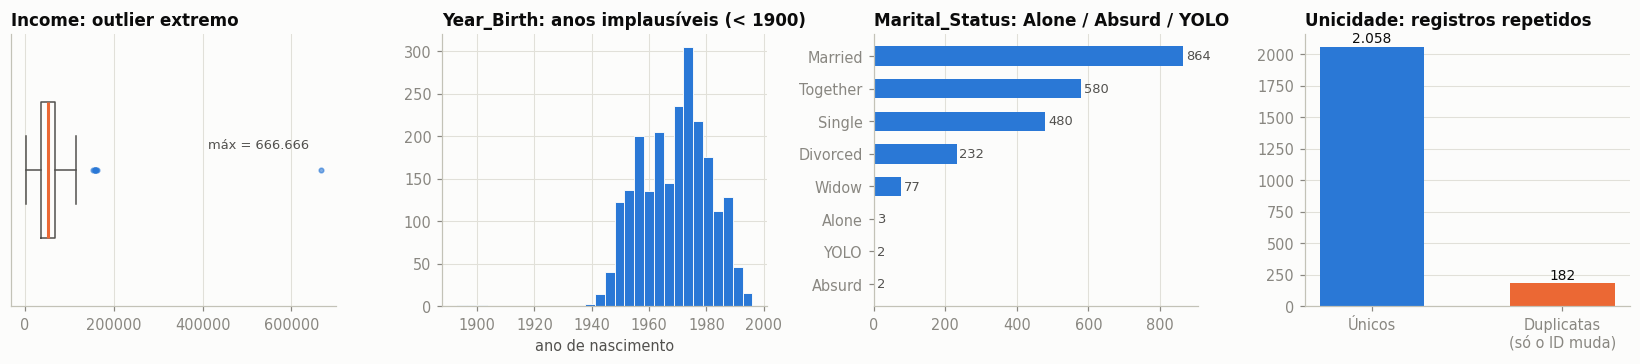

**Leitura.** `Income` tem 24 nulos e um valor extremo (666.666, ~4× o segundo maior); `Year_Birth` traz anos implausíveis (< 1900); `Marital_Status` tem categorias sem sentido (Alone/Absurd/YOLO); e **182 registros (8,1%) repetem todos os atributos de outro cliente, mudando só o ID**. Tratamentos: regras R1–R11 (seção 6).

In [25]:
_ = graf_qualidade(raw, len(dup_raw), salvar=EVID / "qualidade_outliers_categorias.png")
mostrar_md(f"**Leitura.** `Income` tem 24 nulos e um valor extremo (666.666, ~4× o segundo maior); `Year_Birth` traz anos implausíveis (< 1900); `Marital_Status` tem categorias sem sentido (Alone/Absurd/YOLO); "
           f"e **{len(dup_raw)} registros ({pct(len(dup_raw) / len(raw))}) repetem todos os atributos de outro cliente, mudando só o ID**. Tratamentos: regras R1–R11 (seção 6).")

## P1 · Quantos segmentos naturais existem e qual o perfil de cada um?

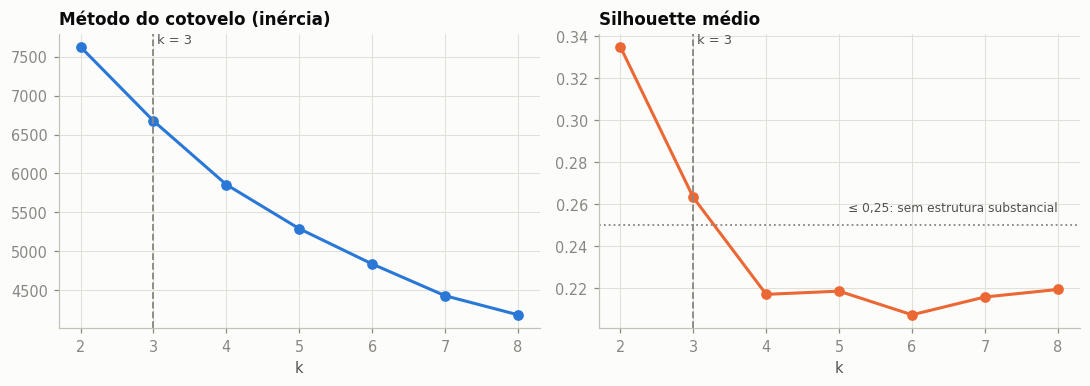

,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,7626.004,0.335,1.211,1273.072
1,3,6674.621,0.263,1.482,873.371
2,4,5856.096,0.217,1.682,759.002
3,5,5289.133,0.219,1.535,684.982
4,6,4835.794,0.207,1.461,637.539
5,7,4427.742,0.216,1.381,611.478
6,8,4182.346,0.219,1.331,571.777


,k,silhouette,ari_medio,ari_min,boot_ari_medio,boot_ari_p05,boot_n,sementes,seed_base
0,3,0.263196,0.999129,0.997822,0.852921,0.405832,30,"[1, 7, 21, 42, 99]",42


In [26]:
rotulos = dict(zip(perfil["segmento_id"], perfil["rotulo"]))
sil_seg = silver.assign(segmento_id=seg_id)                       # silver + segmento (nível do cliente)
fig = graf_escolha_k(metricas, estab["k"], salvar=EVID / "p1_cotovelo_silhouette.png")
display(metricas.round(3)); display(estab_df)

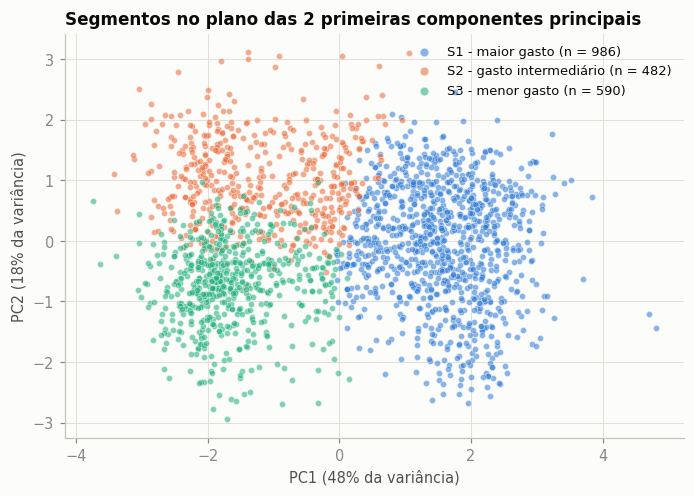

As 2 primeiras componentes explicam 66% da variância (a sobreposição visual reflete o silhouette baixo).


,segmento_id,rotulo,n_clientes,renda_media,idade_media,filhos_medio,pct_com_filhos,gasto_medio,compras_media,recencia_media,ticket_medio,visitas_web_media,tempo_cliente_medio
0,1,S1 - maior gasto,986,69037.0,47.2,0.56,0.517,1108.0,18.8,48.3,59.8,4.06,375.0
1,2,S2 - gasto intermediário,482,44377.0,50.8,1.87,0.996,201.0,8.0,52.3,20.0,6.11,316.0
2,3,S3 - menor gasto,590,29945.0,37.0,0.87,0.832,99.0,5.8,47.2,17.3,6.78,344.0


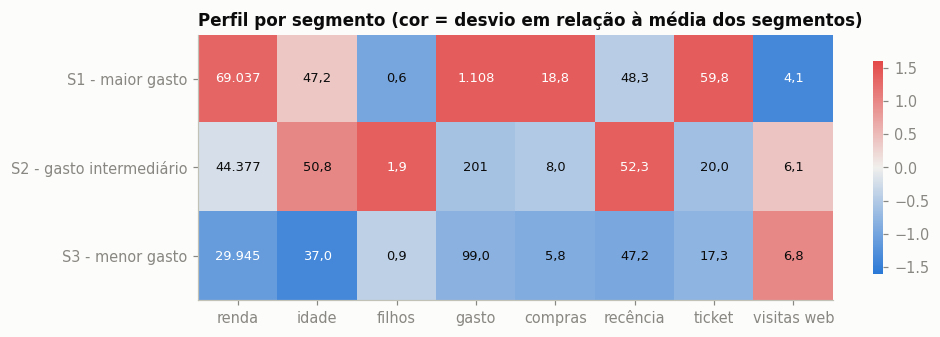

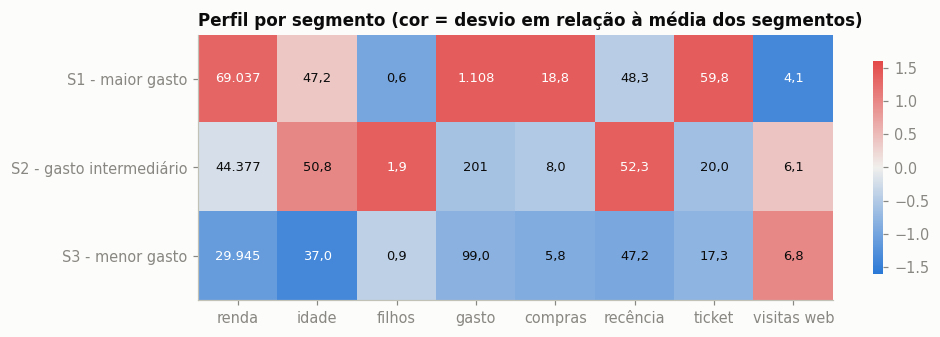

In [27]:
_, var_pca = graf_pca(silver, seg_id, rotulos, salvar=EVID / "p1_pca_segmentos.png")
print(f"As 2 primeiras componentes explicam {pct(var_pca, 0)} da variância (a sobreposição visual reflete o silhouette baixo).")
display(perfil)
graf_perfil(perfil, salvar=EVID / "p1_perfil_segmentos.png")

In [28]:
d_seg, carac = caracterizar_segmentos(sil_seg)
tseg = testes_segmentos(sil_seg)
display(tseg.round(4))
mostrar_md(disc_p1(estab, perfil, carac, tseg))

,variavel,descricao,H,p_valor,epsilon2
0,renda,renda,1429.1310,0.0000,0.6945
1,idade,idade,468.7758,0.0000,0.2271
2,n_filhos,nº de filhos,966.1068,0.0000,0.4692
3,gasto_total,gasto total,1453.8427,0.0000,0.7065
4,compras_total,nº de compras,1427.5561,0.0000,0.6937
5,recencia_dias,recência (dias sem comprar),9.1141,0.0105,0.0035
6,visitas_web_mes,visitas web/mês,525.7304,0.0000,0.2549
7,ticket_medio,ticket médio,1392.3503,0.0000,0.6766
8,pct_compras_desconto,% de compras com desconto,1071.9784,0.0000,0.5207


### Discussão P1 — número e perfil dos segmentos
- **Número de segmentos:** o silhouette, restrito a k entre 3 e 8, apontou k = **3** (silhouette = **0,263** → *estrutura fraca*, pela escala de Kaufman & Rousseeuw). Com silhouette ≤ 0,50 os segmentos são mais um **contínuo de valor** (renda/gasto) do que grupos naturais bem delimitados.
- **Por que não k = 2:** k = 2 teria silhouette maior (0,335), mas apenas separa 'alto' de 'baixo' valor, o que é pouco acionável. Exigir k ≥ 3 é uma **decisão de negócio declarada**, não um achado estatístico.
- **Estabilidade:** ARI médio entre 5 sementes = **0,999** (mínimo 0,998): o algoritmo converge sempre à mesma partição. Em 30 reamostragens bootstrap o ARI médio é **0,85** (5% piores: 0,41): as fronteiras entre segmentos mudam com a amostra, coerente com o silhouette baixo.
- **Perfis:**
  - **S1 - maior gasto** — 986 clientes (47,9%); renda média 69.037, 0,56 filhos em média, gasto médio 1.108; nº de compras muito acima da média (d = +0,87); gasto total muito acima da média (d = +0,83); renda acima da média (d = +0,79).
  - **S2 - gasto intermediário** — 482 clientes (23,4%); renda média 44.377, 1,87 filhos em média, gasto médio 201; nº de filhos muito acima da média (d = +1,23); % de compras com desconto muito acima da média (d = +0,89); gasto total abaixo da média (d = -0,67).
  - **S3 - menor gasto** — 590 clientes (28,7%); renda média 29.945, 0,87 filhos em média, gasto médio 99; renda muito abaixo da média (d = -1,03); nº de compras muito abaixo da média (d = -0,94); gasto total muito abaixo da média (d = -0,84).
- **Diferenças entre segmentos (Kruskal–Wallis):** significativas (p < 0,001) em 8 de 9 variáveis; maior efeito em *gasto total* (ε² = 0,71). Das 3 variáveis que **não** entraram no K-Means (visitas web, ticket médio, % de compras com desconto), 3 também diferem com p < 0,001. *Cautela:* como o K-Means usa as demais variáveis, o teste nelas é descritivo (diferença garantida pela construção), não uma validação independente.

## P2 · Contribuição de cada segmento para a receita e concentração (Pareto 80%)

,segmento_id,rotulo,n_clientes,gasto_total_segmento,pct_receita,pct_clientes,gasto_medio_cliente
0,1,S1 - maior gasto,986,1092485.0,0.8756,0.4791,1108.0
1,2,S2 - gasto intermediário,482,96702.0,0.0775,0.2342,200.6
2,3,S3 - menor gasto,590,58456.0,0.0469,0.2867,99.1


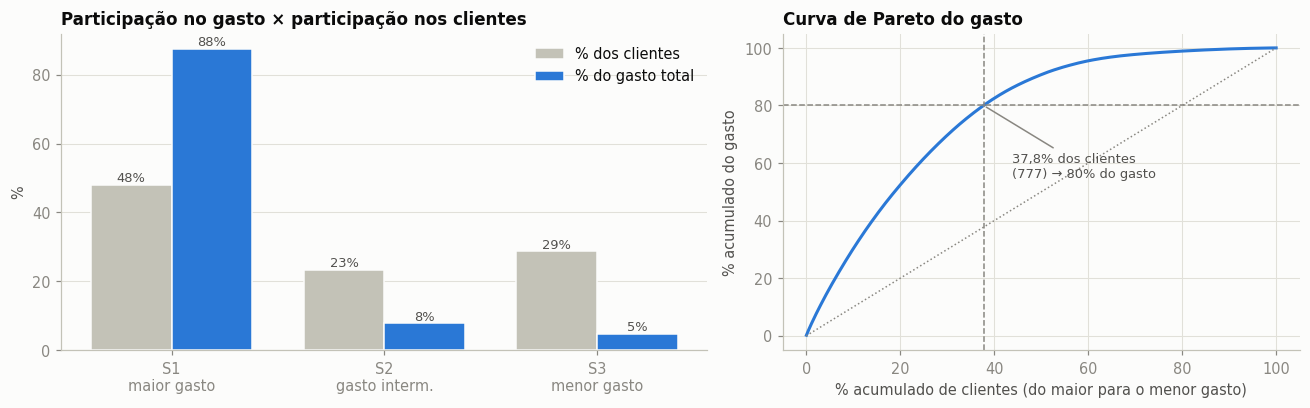

### Discussão P2 — contribuição para a receita e concentração
- **Receita por segmento:** o segmento **S1 - maior gasto** responde por **87,6%** do gasto com **47,9%** dos clientes; gasto médio por cliente de 1.108 contra 99 em S3 - menor gasto (**11,2×** maior).
- **Pareto:** **37,8%** dos clientes (777 de 2.058) concentram 80% do gasto; coeficiente de Gini = 0,54. Concentração **menor** que a regra 80/20 clássica (a concentração é mais distribuída).
- **Implicação comercial:** priorizar S1 - maior gasto cobre 88% do gasto com 48% da base. *Ressalva:* 'receita' aqui é o gasto acumulado em 2 anos, não margem nem lucro.

In [29]:
rec = sql(f"SELECT * FROM {T('vw_receita_segmento')} ORDER BY segmento_id")
par = pareto(sil_seg["gasto_total"])
display(rec)
graf_receita_pareto(rec, par, salvar=EVID / "p2_receita_pareto.png")
mostrar_md(disc_p2(rec, par))

## P3 · Mix de categorias, canais, visitas web e compras com desconto

,segmento_id,rotulo,mix_vinhos,mix_carnes,mix_peixes,mix_frutas,mix_doces,mix_ouro,canal_loja,canal_web,canal_catalogo,pct_compras_desconto,visitas_web_media
0,1,S1 - maior gasto,0.503221,0.283470,0.062027,0.043517,0.045115,0.062649,0.438617,0.307642,0.253740,0.116824,4.061866
1,2,S2 - gasto intermediário,0.581870,0.202395,0.040216,0.028872,0.030558,0.116089,0.500130,0.375162,0.124708,0.394648,6.105809
2,3,S3 - menor gasto,0.332592,0.271606,0.088460,0.062560,0.063073,0.181709,0.534619,0.378323,0.087058,0.330704,6.779661


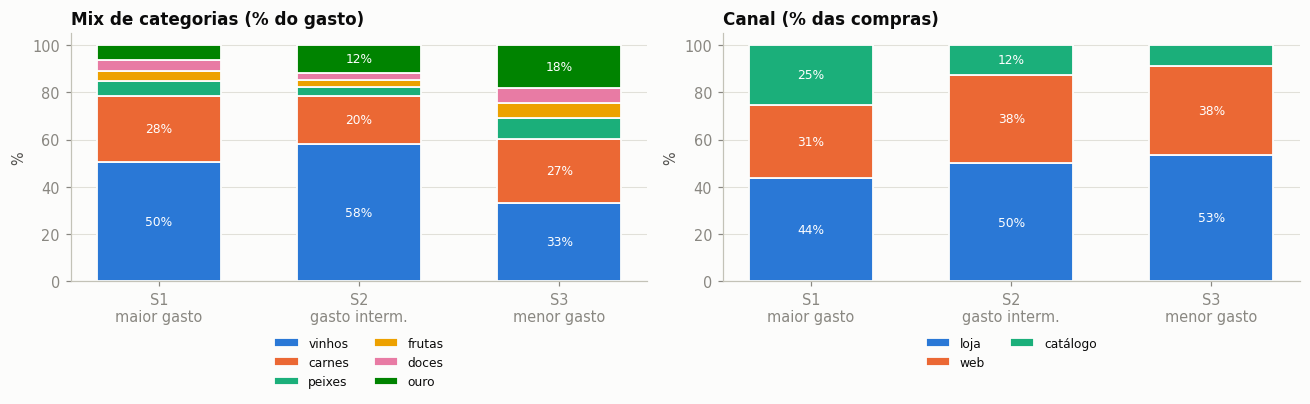

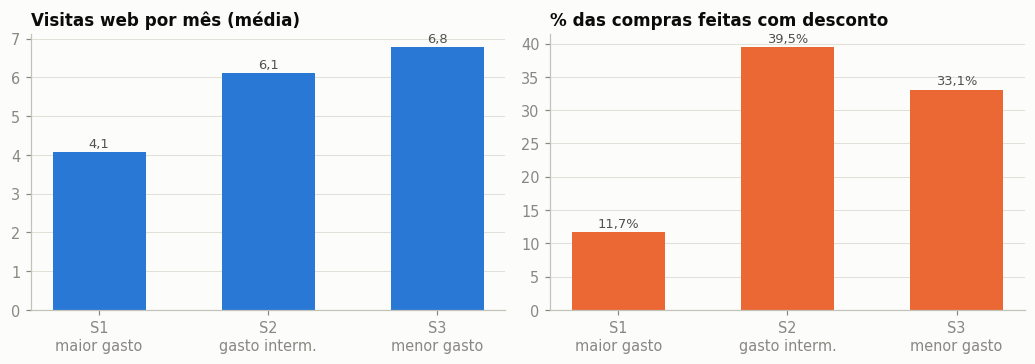

,x,y,rho,p_valor
0,visitas_web_mes,pct_compras_desconto,0.5897,0.0
1,visitas_web_mes,gasto_total,-0.4671,0.0
2,pct_compras_desconto,gasto_total,-0.6711,0.0
3,renda,visitas_web_mes,-0.6370,0.0


### Discussão P3 — categorias, canais, visitas web e desconto
- **Mix:** vinhos representam **50,1%** do gasto total; os segmentos diferem principalmente em **vinhos** (de 33% em S3 - menor gasto a 58% em S2 - gasto intermediário) e **ouro** (de 6% em S1 - maior gasto a 18% em S3 - menor gasto).
- **Canal:** a loja física concentra **46,1%** das compras (web 32,7%, catálogo 21,2%). O maior uso da web está em S3 - menor gasto (38%) e do catálogo em S1 - maior gasto (25%).
- **Visitas web e desconto:** S3 - menor gasto tem mais visitas por mês (6,8) e S2 - gasto intermediário a maior fatia de compras com desconto (39%). No nível do cliente (Spearman): visitas × % desconto ρ = 0,59 (forte); visitas × gasto ρ = -0,47 (moderada); % desconto × gasto ρ = -0,67 (forte). São **associações**, não causalidade: a base não permite inferir por que o cliente visita o site ou compra com desconto.

In [30]:
mix = sql(f"SELECT * FROM {T('vw_mix_canal_segmento')} ORDER BY segmento_id")
display(mix)
graf_mix_canal(mix, salvar=EVID / "p3_mix_canal.png")
graf_visitas_desconto(mix, salvar=EVID / "p3_visitas_desconto.png")
glob = globais_mix(silver)
corr = correlacoes_associacao(sil_seg)
display(corr.round(4))
mostrar_md(disc_p3(mix, glob, corr))

## P4 · Aceitação de campanhas e retorno estimado por segmento
**Premissa declarada:** a base **não documenta** `Z_CostContact` e `Z_Revenue`. Assumimos custo por contato = `Z_CostContact` (3) e receita por aceite = `Z_Revenue` (11), e que **cada cliente foi contatado nas 6 campanhas** (1 a 5 e a última). Os resultados abaixo dependem inteiramente dessa premissa.

,segmento_id,rotulo,contatos,aceites,taxa,ic_lo,ic_hi,custo,receita,retorno,roi,receita_equilibrio
0,1,S1 - maior gasto,5916,714,0.1207,0.1126,0.1292,17748.0,7854.0,-9894.0,-0.5575,24.8571
1,2,S2 - gasto intermediário,2892,96,0.0332,0.0273,0.0404,8676.0,1056.0,-7620.0,-0.8783,90.3750
2,3,S3 - menor gasto,3540,121,0.0342,0.0287,0.0407,10620.0,1331.0,-9289.0,-0.8747,87.7686


,campanha_id,contatos,aceites,taxa,nome
0,1,2058,135,0.0656,Campanha 1
1,2,2058,26,0.0126,Campanha 2
2,3,2058,151,0.0734,Campanha 3
3,4,2058,158,0.0768,Campanha 4
4,5,2058,148,0.0719,Campanha 5
5,6,2058,313,0.1521,Última campanha


,campanha_id,nome,chi2,gl,p_valor,cramer_v,esperado_min
0,1,Campanha 1,135.7242,2,0.000,0.2568,31.6181
1,2,Campanha 2,21.1642,2,0.000,0.1014,6.0894
2,3,Campanha 3,3.9042,2,0.142,0.0436,35.3654
3,4,Campanha 4,104.2985,2,0.000,0.2251,37.0049
4,5,Campanha 5,164.5664,2,0.000,0.2828,34.6628
5,6,Última campanha,43.6941,2,0.000,0.1457,73.3071


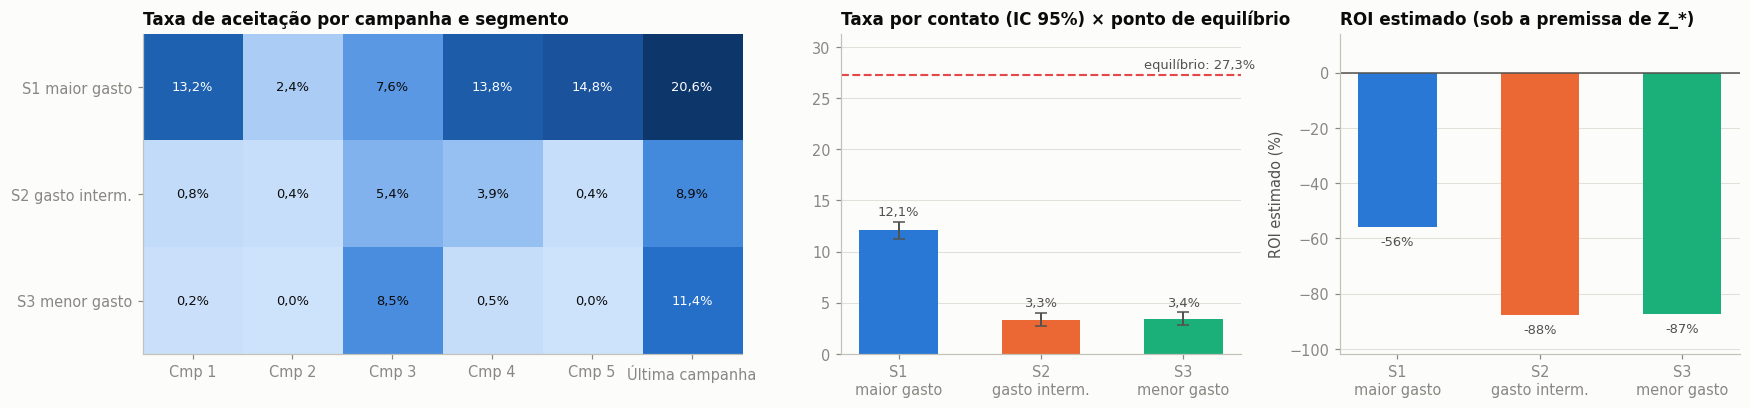

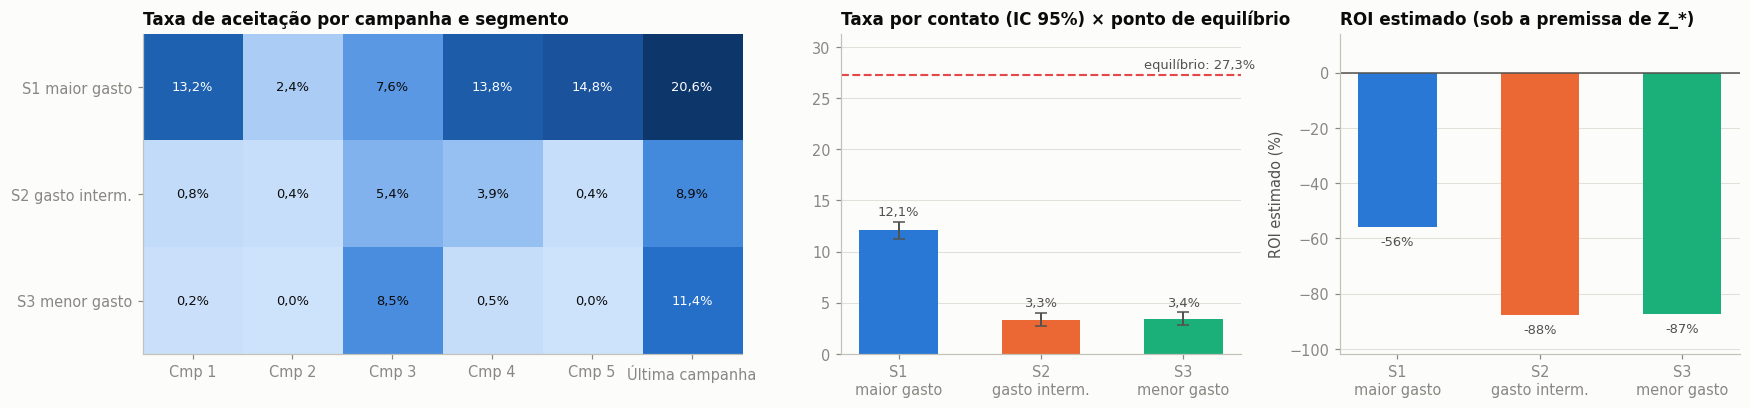

In [31]:
fc = ler_tabela("fato_campanha_resposta"); dim_camp = ler_tabela("dim_campanha"); dim_seg = ler_tabela("dim_segmento")
g_sc, camp_seg = tabela_campanhas(fc, dim_camp, dim_seg, CUSTO_CONTATO, RECEITA_ACEITE)
camp_cmp = por_campanha(fc, dim_camp)
tc = testes_campanhas(fc, dim_camp)
# conferência cruzada: a visão SQL (formato largo) e a fato longa devem dar os mesmos aceites e contatos
v_camp = sql(f"SELECT * FROM {T('vw_campanhas_segmento')} ORDER BY segmento_id")
assert (v_camp["aceites"].values == camp_seg.sort_values("segmento_id")["aceites"].values).all(), "visão SQL e fato longa divergem em aceites"
assert (v_camp["contatos"].values == camp_seg.sort_values("segmento_id")["contatos"].values).all(), "visão SQL e fato longa divergem em contatos"
display(camp_seg.round(4)); display(camp_cmp.round(4)); display(tc.round(4))
BREAK_EVEN = CUSTO_CONTATO / RECEITA_ACEITE
graf_campanhas(g_sc, camp_seg, BREAK_EVEN, salvar=EVID / "p4_campanhas_roi.png")

In [32]:
# Sensibilidade do ROI à receita por aceite (a premissa Z_Revenue é o ponto mais frágil de P4)
mult = [1, 2, 3, 4]
sens = pd.DataFrame({"segmento": camp_seg["rotulo"]})
for m in mult:
    sens[f"ROI com receita = {br(RECEITA_ACEITE * m, 0)}"] = ((camp_seg["aceites"] * RECEITA_ACEITE * m - camp_seg["custo"]) / camp_seg["custo"]).map(lambda x: pct(x, 0))
sens["receita p/ ROI = 0"] = camp_seg["receita_equilibrio"].map(lambda x: br(x, 1))
display(sens)
mostrar_md(disc_p4(camp_seg, camp_cmp, g_sc, tc, CUSTO_CONTATO, RECEITA_ACEITE))

,segmento,ROI com receita = 11,ROI com receita = 22,ROI com receita = 33,ROI com receita = 44,receita p/ ROI = 0
0,S1 - maior gasto,-56%,-11%,33%,77%,"24,9"
1,S2 - gasto intermediário,-88%,-76%,-63%,-51%,"90,4"
2,S3 - menor gasto,-87%,-75%,-62%,-50%,"87,8"


### Discussão P4 — campanhas e retorno estimado
- **Aceitação por campanha:** de **1,3%** (Campanha 2) a **15,2%** (Última campanha); taxa média por contato = 7,5%. Por segmento, a taxa agregada vai de 3,3% (S2 - gasto intermediário) a 12,1% (S1 - maior gasto).
- **Diferença entre segmentos (qui-quadrado):** p < 0,05 em 5 de 6 campanhas (Campanha 1, Campanha 2, Campanha 4, Campanha 5, Última campanha).
- **Ponto de equilíbrio:** com custo de 3 por contato e receita de 11 por aceite, cada contato precisa de taxa ≥ **27,3%** para ROI ≥ 0. **Nenhuma** combinação segmento × campanha atinge esse patamar (máximo observado: 20,6% — S1 - maior gasto, Última campanha).
- **Retorno estimado:** o ROI é **negativo** (em todos os segmentos): melhor = **S1 - maior gasto** (ROI -56%), pior = S2 - gasto intermediário (ROI -88%); base toda: -72%. O ranking mostra qual segmento é **menos ineficiente**, não qual dá lucro.
- **Sensibilidade à premissa:** para ROI = 0, a receita por aceite precisaria ser de 25 em S1 - maior gasto; 90 em S2 - gasto intermediário; 88 em S3 - menor gasto (premissa atual: 11). Se `Z_*` tiver outro significado, a conclusão pode mudar.
- **Limites:** `Response` refere-se a **uma única campanha**; não há custo real, margem nem registro de quem foi de fato contatado (a premissa é que todos foram, em todas as campanhas).

## P5 · Clientes de alto gasto e recência alta (risco de inatividade)
Definição: gasto total ≥ percentil `PCT_RISCO_GASTO` **e** dias desde a última compra ≥ percentil `PCT_RISCO_RECENCIA`. (Na base, `Recency` = dias desde a última compra; valor alto = cliente parado há mais tempo.)

131 clientes em risco (6,4% da base) | gasto somado: 196.573


,cliente_id,rotulo,gasto_total,recencia_dias,compras_total,compras_loja,compras_web,compras_catalogo,n_campanhas_aceitas,campanha_ultima
0,4475,S1 - maior gasto,2440,82,24,9,7,8,0,0
1,9010,S1 - maior gasto,2346,80,22,10,5,7,3,1
2,2147,S1 - maior gasto,2279,91,22,11,4,7,2,0
3,7274,S1 - maior gasto,2153,87,21,10,4,7,1,0
4,2747,S1 - maior gasto,2126,90,19,5,4,10,0,0
5,6932,S1 - maior gasto,2119,77,22,5,7,10,1,0
6,5830,S1 - maior gasto,2114,96,21,10,5,6,0,1
7,313,S1 - maior gasto,2088,98,21,10,6,5,1,0
8,4910,S1 - maior gasto,2074,81,29,13,11,5,0,0
9,3010,S1 - maior gasto,2069,87,19,8,4,7,3,0


,rotulo,clientes,gasto,recencia_media
0,S1 - maior gasto,127,190689,86.291339
1,S2 - gasto intermediário,4,5884,91.500000


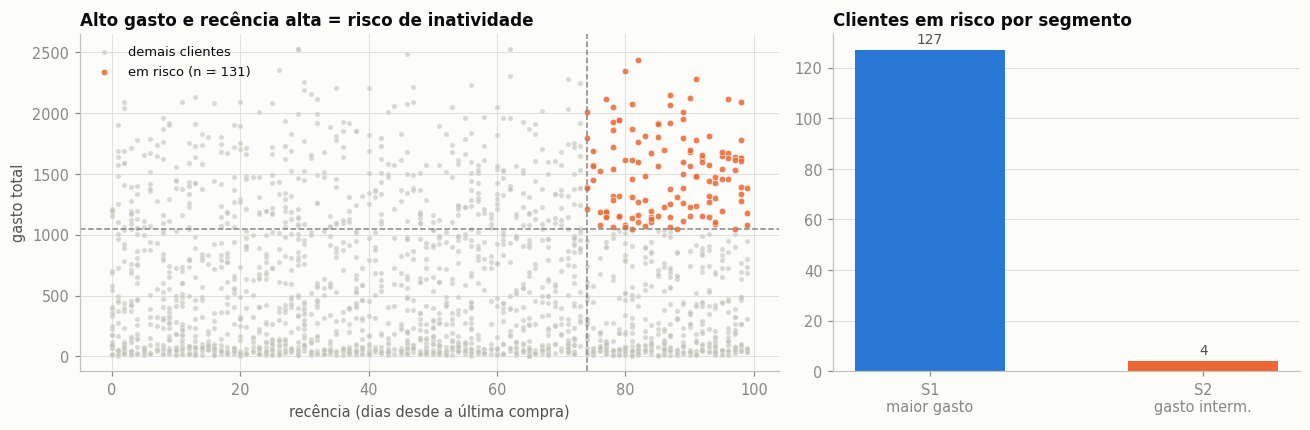

### Discussão P5 — clientes de alto gasto e recência alta
- **Tamanho do risco:** **131** clientes (6,4% da base; gasto somado de 196.573 = 15,8% do gasto total) têm gasto ≥ 1.047 (percentil 75) **e** recência ≥ 74 dias (percentil 75); 97% deles estão em **S1 - maior gasto**. Se gasto e recência fossem independentes, esperaríamos ~6,2% da base nessa região: o valor observado indica **pouca associação** entre gastar muito e ficar parado.
- **Ação sugerida:** contato proativo e personalizado pelo canal preferido do cliente (loja/web/catálogo), com oferta ligada à categoria dominante dele (ver P3); medir reativação em 30–60 dias.
- **Cautela:** recência alta pode refletir ciclo de compra natural (ex.: vinho premium), não abandono; validar com histórico de compras, que a base não traz.

In [33]:
risco = sql(f"SELECT * FROM {T('vw_clientes_risco')} ORDER BY gasto_total DESC")
lim_g, lim_r = float(risco["lim_gasto"].iloc[0]), float(risco["lim_rec"].iloc[0])
n_base, gasto_base = len(silver), float(silver["gasto_total"].sum())
por_seg_risco = (risco.groupby("rotulo").agg(clientes=("cliente_id", "count"), gasto=("gasto_total", "sum"), recencia_media=("recencia_dias", "mean"))
                 .reset_index().sort_values("rotulo"))
print(f"{len(risco)} clientes em risco ({pct(len(risco) / n_base)} da base) | gasto somado: {br(risco['gasto_total'].sum())}")
display(risco.drop(columns=["lim_gasto", "lim_rec"]).head(20)); display(por_seg_risco)
graf_risco(sil_seg, lim_g, lim_r, por_seg_risco, salvar=EVID / "p5_clientes_risco.png")
mostrar_md(disc_p5(risco, por_seg_risco, n_base, gasto_base, lim_g, lim_r, PCT_RISCO_GASTO, PCT_RISCO_RECENCIA))

## Robustez: os resultados mudam se as duplicatas forem mantidas?

In [34]:
def cenario(remover):
    s, _, const, dup = silver_transform(bronze, remover_duplicatas=remover)
    sid, met, est = clusterizar(s, k_max=K_MAX, k_min_escolha=K_MIN_ESCOLHA, seed=SEED, n_boot=10)
    tmp = s.assign(segmento_id=sid)
    por = tmp.groupby("segmento_id")["gasto_total"].agg(["count", "sum"])
    lg, lr = np.quantile(s["gasto_total"], PCT_RISCO_GASTO, method="inverted_cdf"), np.quantile(s["recencia_dias"], PCT_RISCO_RECENCIA, method="inverted_cdf")
    n_risco = int(((s["gasto_total"] >= lg) & (s["recencia_dias"] >= lr)).sum())
    roi = tmp[COLS_CAMPANHA].sum().sum() * const["Z_Revenue"] / (len(s) * N_CONTATOS_POR_CLIENTE * const["Z_CostContact"]) - 1
    return {"cenário": "duplicatas removidas" if remover else "duplicatas mantidas", "clientes": len(s), "k": est["k"],
            "silhouette": est["silhouette_k"], "S1 % clientes": por.loc[1, "count"] / len(s), "S1 % gasto": por.loc[1, "sum"] / por["sum"].sum(),
            "Pareto: % clientes p/ 80% gasto": pareto(s["gasto_total"])["frac80"], "clientes em risco (P5)": n_risco, "ROI global estimado (P4)": roi}
rob_num = pd.DataFrame([cenario(True), cenario(False)])
a, b = rob_num.iloc[0], rob_num.iloc[1]
robustez = rob_num.copy()
for c in ["S1 % clientes", "S1 % gasto", "Pareto: % clientes p/ 80% gasto", "ROI global estimado (P4)"]:
    robustez[c] = rob_num[c].map(lambda x: pct(x, 1))
robustez["silhouette"] = rob_num["silhouette"].round(3)
robustez.to_csv(TAB / "robustez_duplicatas.csv", index=False)
display(robustez.set_index("cenário").T)
estavel = (a["k"] == b["k"] and abs(a["silhouette"] - b["silhouette"]) < 0.02 and abs(a["S1 % gasto"] - b["S1 % gasto"]) < 0.02
           and abs(a["Pareto: % clientes p/ 80% gasto"] - b["Pareto: % clientes p/ 80% gasto"]) < 0.02
           and np.sign(a["ROI global estimado (P4)"]) == np.sign(b["ROI global estimado (P4)"]))
mostrar_md(("**Leitura.** Mantendo ou removendo as duplicatas, k, separação (silhouette), participação do S1 no gasto, concentração de Pareto e sinal do ROI praticamente não mudam: "
            "**as conclusões não dependem desse tratamento**. A remoção é adotada por rigor de unicidade e a comparação fica registrada aqui. "
            f"A principal diferença está no tamanho do grupo de risco de P5 ({int(a['clientes em risco (P5)'])} sem duplicatas contra {int(b['clientes em risco (P5)'])} com elas)."
            if estavel else
            "**Leitura.** Os resultados **mudam de forma relevante** entre os dois cenários (ver tabela): o tratamento das duplicatas afeta as conclusões e deve ser discutido no relatório."))

cenário,duplicatas removidas,duplicatas mantidas
clientes,2058,2240
k,3,3
silhouette,0.263,0.264
S1 % clientes,"47,9%","47,7%"
S1 % gasto,"87,6%","87,5%"
Pareto: % clientes p/ 80% gasto,"37,8%","37,7%"
clientes em risco (P5),131,145
ROI global estimado (P4),"-72,4%","-72,7%"


**Leitura.** Mantendo ou removendo as duplicatas, k, separação (silhouette), participação do S1 no gasto, concentração de Pareto e sinal do ROI praticamente não mudam: **as conclusões não dependem desse tratamento**. A remoção é adotada por rigor de unicidade e a comparação fica registrada aqui. A principal diferença está no tamanho do grupo de risco de P5 (131 sem duplicatas contra 145 com elas).

## Discussão geral e playbook comercial

In [35]:
texto_geral, veredito = disc_geral(estab, tseg, camp_seg, tc, par)
mostrar_md(texto_geral)
mostrar_md(playbook(perfil, mix, rec, camp_seg, carac, por_seg_risco, len(risco), float(risco["gasto_total"].sum()), gasto_base))
periodo = f"{silver['data_cadastro'].min().year}–{silver['data_cadastro'].max().year}"
mostrar_md(limitacoes(periodo, len(dup_raw), REMOVER_DUPLICATAS))

## Discussão geral
**Hipótese testada:** existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes? → **PARCIALMENTE CONFIRMADA**.
*Regra do veredito (explícita):* confirmada se o efeito em gasto é grande (ε² ≥ 0,14), há diferença de resposta em campanhas (p < 0,05 em ao menos uma) **e** silhouette > 0,50; parcialmente se falta separação (silhouette ≤ 0,50) ou diferença de resposta; não confirmada se o efeito em gasto é pequeno.
- **Valor:** diferenças grandes de gasto entre segmentos (ε² = 0,71); 37,8% dos clientes concentram 80% do gasto.
- **Separação:** silhouette = 0,263 (estrutura fraca); estabilidade bootstrap (ARI médio) = 0,85.
- **Resposta a campanhas:** diferença entre segmentos em 5 de 6 campanhas (p < 0,05).
- **Retorno:** ROI estimado negativo em todos os segmentos sob a premissa Z_*: a segmentação ajuda a **priorizar** (onde a perda é menor), mas não demonstra que as campanhas se pagam.

### Playbook comercial (uma ação por segmento)
| Segmento | Perfil resumido | Oferta | Canal | Prioridade |
|---|---|---|---|---|
| S1 - maior gasto | 986 clientes (48%); renda média 69.037; nº de compras muito acima da média (d = +0,87); gasto total muito acima da média (d = +0,83); renda acima da média (d = +0,79) | curadoria e fidelização em vinhos (50% do gasto) e carnes; desconto pouco usado (12% das compras) | loja (44% das compras); apoio: web (31%) | **Alta** — 88% do gasto; ROI estimado -56% |
| S2 - gasto intermediário | 482 clientes (23%); renda média 44.377; nº de filhos muito acima da média (d = +1,23); % de compras com desconto muito acima da média (d = +0,89); gasto total abaixo da média (d = -0,67) | cross-sell de vinhos (58% do gasto) para carnes (20%) | loja (50% das compras); apoio: web (38%) | **Média** — ROI estimado -88% |
| S3 - menor gasto | 590 clientes (29%); renda média 29.945; renda muito abaixo da média (d = -1,03); nº de compras muito abaixo da média (d = -0,94); gasto total muito abaixo da média (d = -0,84) | ofertas de entrada em vinhos e carnes; promoções pontuais (33% das compras já usam desconto) | loja (53% das compras); apoio: web (38%) | **Baixa** — comunicação automatizada de baixo custo; ROI estimado -87% |
| Clientes em risco (P5) | 131 clientes; 16% do gasto total | reativação personalizada, ligada à categoria dominante de cada cliente | canal preferido do cliente | **Alta** |

### Limitações
- Dados de 2012–2014 (defasados); sem custo/margem por produto; o significado de `Z_*` é premissa; `Response` é de uma campanha; amostra com possível viés de seleção (não se sabe como os clientes foram escolhidos); segmentos pouco separados limitam a generalização.
- 182 registros duplicados (todos os atributos iguais, exceto o ID) foram removidos da Silver; não é possível saber se são erro de carga ou clientes distintos com perfil idêntico (improvável com 28 atributos).
- K-Means assume grupos esféricos e usa variáveis correlacionadas (gasto, compras, renda); outros algoritmos (GMM, hierárquico) não foram comparados.

## 10. Ética, licenciamento e LGPD (seção 4 do PDF)
- **Licença:** a base declara **CC0 (domínio público)**, que permite redistribuição e uso derivado. *Confirme na página do dataset e registre a data na seção 2.* O repositório referencia a fonte (link do Kaggle) e o `sha256`.
- **Dados pessoais (Lei 13.709/2018):** o conjunto **não tem identificadores diretos** (nome, CPF, e-mail, endereço); `ID` é sequencial, sem ligação com sistema real. Há **quase-identificadores** (ano de nascimento, escolaridade, estado civil, renda, filhos).
- **Risco de reidentificação:** medido abaixo por *k*-anonimato. Procedimento adotado: usar **faixas** (faixa etária, quartil de renda) nas dimensões analíticas e não publicar listas individuais com o conjunto completo de atributos.
- **Dados corporativos:** não se aplica (base pública).

In [36]:
def k_anon(df, cols):
    tam = df.groupby(cols).size()
    return {"quase-identificadores": " + ".join(cols), "grupos": len(tam), "menor grupo (k)": int(tam.min()),
            "% clientes em grupos < 5": round(100 * tam[tam < 5].sum() / len(df), 1)}
dc = gold["dim_cliente"].merge(gold["fato_cliente_vendas"][["cliente_id", "educacao_id", "estado_civil_id"]], on="cliente_id")
risco_reid = pd.DataFrame([
    k_anon(silver, ["ano_nascimento", "educacao", "estado_civil", "n_filhos"]),
    k_anon(dc, ["faixa_etaria", "educacao_id", "estado_civil_id", "tem_filhos"]),
    k_anon(dc, ["faixa_etaria", "faixa_renda", "educacao_id", "tem_filhos"]),
])
risco_reid.to_csv(CAT / "risco_reidentificacao.csv", index=False)
display(risco_reid)
mostrar_md(f"**Leitura.** Com atributos exatos (1ª linha), **{br(risco_reid.iloc[0]['% clientes em grupos < 5'], 1)}%** dos clientes estão em grupos com menos de 5 pessoas; "
           f"usando faixas (linhas 2 e 3) cai para **{br(risco_reid.iloc[1]['% clientes em grupos < 5'], 1)}%** e **{br(risco_reid.iloc[2]['% clientes em grupos < 5'], 1)}%**. "
           "Por isso o MVP trabalha com faixas e não expõe registros individuais além de `cliente_id` + métricas. O risco prático é baixo (base pública, sem nome/contato), mas não é zero.")

,quase-identificadores,grupos,menor grupo (k),% clientes em grupos < 5
0,ano_nascimento + educacao + estado_civil + n_f...,1056,1,81.2
1,faixa_etaria + educacao_id + estado_civil_id +...,188,1,9.1
2,faixa_etaria + faixa_renda + educacao_id + tem...,150,1,6.6


**Leitura.** Com atributos exatos (1ª linha), **81,2%** dos clientes estão em grupos com menos de 5 pessoas; usando faixas (linhas 2 e 3) cai para **9,1%** e **6,6%**. Por isso o MVP trabalha com faixas e não expõe registros individuais além de `cliente_id` + métricas. O risco prático é baixo (base pública, sem nome/contato), mas não é zero.

## 11. Diagrama do modelo, exportação e evidências

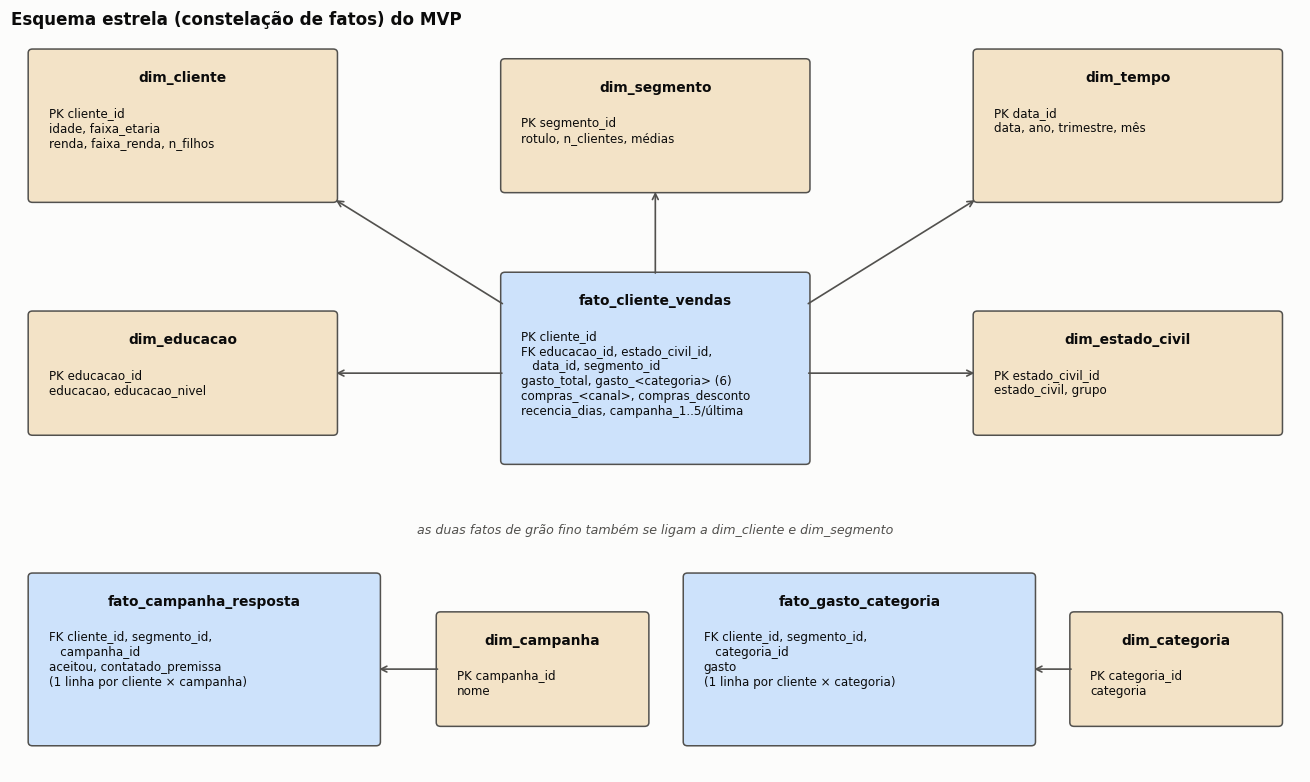

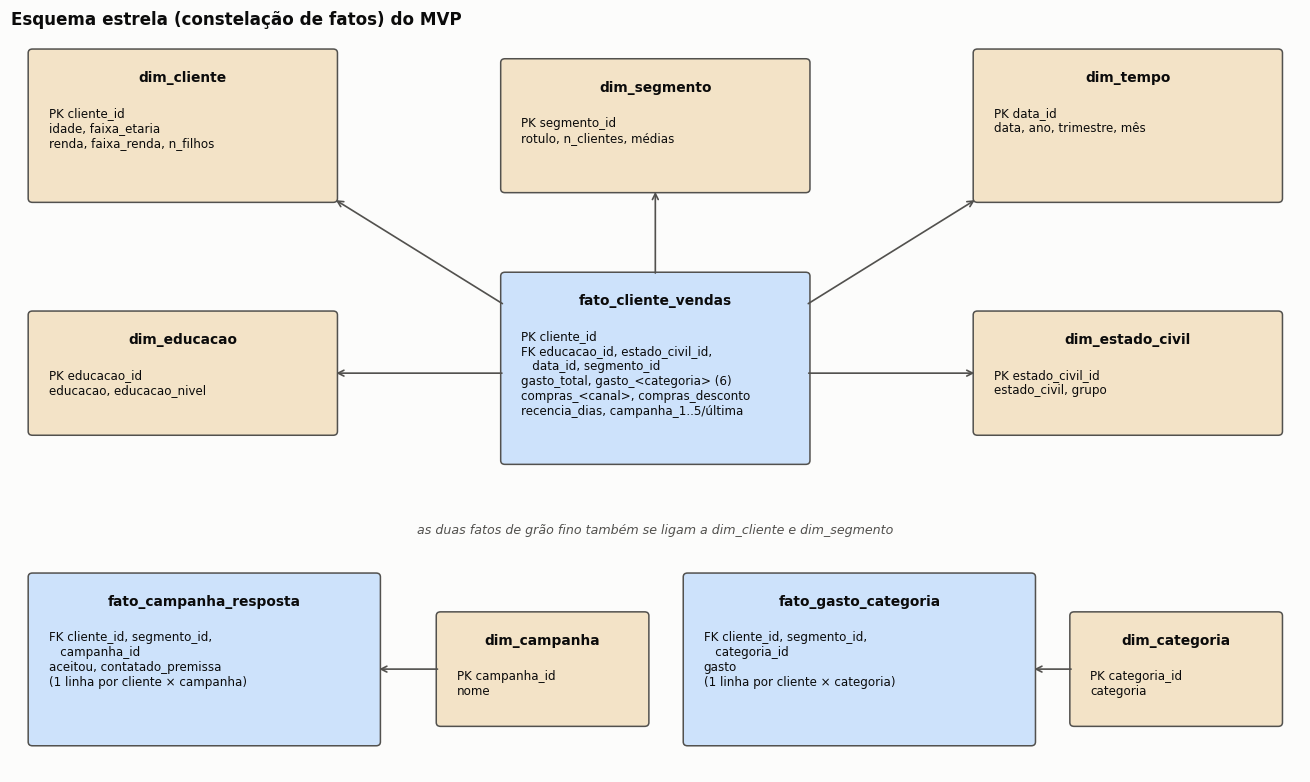

In [37]:
(CAT / "diagrama_estrela.md").write_text("# Diagrama do esquema estrela\n\n" + MERMAID_ESTRELA, encoding="utf-8")
graf_estrela(salvar=CAT / "diagrama_estrela.png")

In [38]:
# Resumo numérico de tudo o que alimenta o relatório (JSON) + tabelas em CSV + pacote .zip
def _py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp, dt.date)): return str(o)
    return str(o)

resumo = {
    "ambiente": AMBIENTE, "coleta": meta, "parametros": {"seed": SEED, "k_max": K_MAX, "k_min_escolha": K_MIN_ESCOLHA, "remover_duplicatas": REMOVER_DUPLICATAS,
                                                       "pct_risco_gasto": PCT_RISCO_GASTO, "pct_risco_recencia": PCT_RISCO_RECENCIA,
                                                       "custo_contato": CUSTO_CONTATO, "receita_aceite": RECEITA_ACEITE, "contatos_por_cliente": N_CONTATOS_POR_CLIENTE},
    "qualidade": qualidade.to_dict("records"), "regras_silver": log_regras.to_dict("records"),
    "clusterizacao": {"estabilidade": estab, "metricas": metricas.to_dict("records")},
    "segmentos": perfil.to_dict("records"), "receita_segmento": rec.to_dict("records"),
    "pareto": {k: v for k, v in par.items() if k != "curva"}, "mix_canal": mix.to_dict("records"), "globais": glob,
    "correlacoes": corr.to_dict("records"), "testes_segmentos": tseg.to_dict("records"),
    "campanhas_por_segmento": camp_seg.to_dict("records"), "campanhas_por_campanha": camp_cmp.to_dict("records"),
    "testes_campanhas": tc.to_dict("records"), "break_even_taxa": BREAK_EVEN,
    "risco": {"n": len(risco), "pct_base": len(risco) / n_base, "gasto": float(risco["gasto_total"].sum()), "pct_gasto": float(risco["gasto_total"].sum()) / gasto_base,
              "lim_gasto": lim_g, "lim_recencia": lim_r, "por_segmento": por_seg_risco.to_dict("records")},
    "robustez_duplicatas": robustez.to_dict("records"), "veredito_hipotese": veredito,
    "k_anonimato": risco_reid.to_dict("records"),
}
(SAIDA / "resultados_resumo.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False, default=_py), encoding="utf-8")
for nome_t, df_t in {"perfil_segmentos": perfil, "receita_segmento": rec, "mix_canal_segmento": mix, "campanhas_por_segmento": camp_seg,
                     "campanhas_segmento_campanha": g_sc, "testes_segmentos": tseg, "testes_campanhas": tc, "clientes_risco": risco,
                     "metricas_k": metricas, "sensibilidade_roi": sens}.items():
    df_t.to_csv(TAB / f"{nome_t}.csv", index=False)
import zipfile
zip_path = SAIDA.parent / "mvp_unb_resultados.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for base_dir in (EVID, CAT, TAB):
        for arq in sorted(base_dir.rglob("*")):
            if arq.is_file():
                zf.write(arq, arq.relative_to(SAIDA))
    zf.write(SAIDA / "resultados_resumo.json", "resultados_resumo.json")
print("Pacote:", zip_path)
print(*sorted(str(p.relative_to(SAIDA)) for p in SAIDA.rglob("*") if p.is_file() and p.suffix in (".png", ".csv", ".json", ".md")), sep="\n  ")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Pacote: /content/mvp_unb/mvp_unb_resultados.zip
catalogo/catalogo_dados.csv
  catalogo/catalogo_dados.md
  catalogo/diagrama_estrela.md
  catalogo/diagrama_estrela.png
  catalogo/duplicatas_detectadas.csv
  catalogo/metadados_coleta.json
  catalogo/qualidade_por_atributo.csv
  catalogo/qualidade_testes.csv
  catalogo/regras_transformacao.csv
  catalogo/risco_reidentificacao.csv
  evidencias/p1_cotovelo_silhouette.png
  evidencias/p1_pca_segmentos.png
  evidencias/p1_perfil_segmentos.png
  evidencias/p2_receita_pareto.png
  evidencias/p3_mix_canal.png
  evidencias/p3_visitas_desconto.png
  evidencias/p4_campanhas_roi.png
  evidencias/p5_clientes_risco.png
  evidencias/qualidade_outliers_categorias.png
  resultados_resumo.json
  tabelas/campanhas_por_segmento.csv
  tabelas/campanhas_segmento_campanha.csv
  tabelas/clientes_risco.csv
  tabelas/metricas_k.csv
  tabelas/mix_canal_segmento.csv
  tabelas/perfil_segmentos.csv
  tabelas/receita_segmento.csv
  tabelas/robustez_duplicatas.csv
  t

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Evidências de nuvem a capturar (Databricks) e onde referenciá-las
O PDF exige **prova de execução e persistência na nuvem**. Rode este mesmo notebook no Databricks e capture:

| # | Evidência | Onde |
|---|---|---|
| E1 | Volume com o CSV enviado | Catalog → Volumes |
| E2 | Tabelas `bronze_*`, `silver_*`, `dim_*`, `fato_*`, `gold_*` e visões `vw_*` no schema | Catalog → schema |
| E3 | Amostra + `DESCRIBE HISTORY` de uma tabela Delta | Notebook ou SQL Editor |
| E4 | Comentários de coluna (catálogo) em uma tabela | Catalog → tabela → Columns |
| E5 | Job/Workflow com tarefas encadeadas e execução bem-sucedida | Jobs & Pipelines → Runs |
| E6 | Gráficos e discussões de P1–P5 desta execução | Notebook |
| E7 | Repositório aberto em janela anônima | GitHub |

As imagens em `evidencias/` (gráficos desta execução) podem ser usadas no README/relatório e referenciadas no ponto do texto que sustentam.